# PathoLens AI — Standalone End-to-End Laptop GPU Notebook

**Purpose:** one independent notebook to recover/reuse your existing PathoLens workspace, train any missing experiments among E1–E4, select the model using validation Macro-F1, run the remaining evaluation and explainability analyses, and export an inference-ready checkpoint bundle plus a final report.

## What this notebook does

1. Uses the local `PathoLens_Workspace` folder beside this notebook (or the path set in the configuration cell).
2. Verifies the dataset subset, manifest, class mapping, pretrained-weight identity, and checkpoint compatibility.
3. **Reuses all four existing `best_model.pt` checkpoints when they are valid.** It does not retrain a completed experiment just because this is a new notebook.
4. If an experiment checkpoint is missing, it resumes from a matching `last_checkpoint.pt`; if neither exists, it trains that experiment.
5. Runs the four fixed experiments: E1 RGB baseline, E2 HED stain augmentation, E3 Macenko normalization, and E4 multi-scale MobileNetV3-Small.
6. Selects the winner from `val_select` Macro-F1 only. `val_calib` is reserved for temperature scaling and the abstention threshold.
7. Evaluates all four experiments on the held-out test subset, then runs calibration, entropy, selective prediction, risk–coverage, confusion/error analysis, Grad-CAM, Grad-CAM sanity/stability checks, PCA, and efficiency profiling for the validation-selected winner.
8. Saves CSVs, figures, checkpoint verification details, a final Markdown report, and an inference bundle under the workspace.

## Run location and existing files

Place this notebook in the same project folder as your existing laptop notebook. By default it looks for:

```text
<project-folder>/PathoLens_Workspace/
    shared_dataset/
    pretrained/
    derived_data/
    experiments/E1..E4/
    logs/
    figures/
    metadata/
    exports/
```

The existing `PathoLens_Laptop_GPU.ipynb` is not modified. This notebook is a separate, self-contained copy of the same training pipeline with stricter checkpoint reuse and additional post-training analysis.

## Experiments (unchanged)

- **E1:** MobileNetV3-Small, original RGB baseline.
- **E2:** same MobileNetV3-Small architecture with controlled H&E stain perturbation during training.
- **E3:** same MobileNetV3-Small architecture using Macenko normalization fitted from training-subset images only.
- **E4:** multi-scale MobileNetV3-Small with pooled features from three backbone stages.

## Research safeguards

- The checkpoint-selection validation partition and calibration-validation partition remain separate.
- Test metrics are reported for final evaluation only; they never select the winner, temperature, or abstention threshold.
- The dataset is still the fixed **10% PathMNIST-128 pilot subset**, not the full official dataset.
- A sample-ID/duplicate audit does not establish patient- or slide-level independence.
- Grad-CAM is a model-activation visualization, not a segmentation mask or proof of biological reasoning.
- This is a research prototype, not a clinically validated diagnostic system.


## 50% dataset run — separate workspace

This version samples **50% of each official PathMNIST train, validation, and test split**, stratified by class with seed 42. It writes to `PathoLens_Workspace_50pct/`, not the existing 10% workspace. Therefore, the 10% checkpoints and subset cache are not reused. The four experiments (E1–E4) will train on the new 50% subset; if this run is interrupted, matching checkpoints in this 50% workspace can be resumed.

**Do not copy 10% checkpoints into this workspace.** Their training data and experiment signatures do not match the 50% subset. Test data remains held out for final descriptive evaluation; model selection is based on validation Macro-F1.


## Laptop memory and GPU safeguards

This edition is rewritten for a Windows laptop with an NVIDIA RTX 3050 and 16 GB system RAM:
- Uses **50% stratified samples from each official split** (train/validation/test).
- Stores selected RGB images and Macenko-normalized images as disk-backed `.npy` arrays, opened with read-only memory maps. It avoids holding duplicate full image arrays in RAM.
- Uses batch size 8 by default (can reduce to 4 if free VRAM is low) and `num_workers=0` on Windows.
- Requires CUDA and verifies a real CUDA operation before data loading.
- Uses a **new workspace** `PathoLens_Workspace_50pct_v2/` so this revised cache layout cannot conflict with the earlier run.
- Preserves E1–E4 definitions, checkpointing, validation-only model selection, test comparison, Grad-CAM, calibration, uncertainty, rotation stability, and final exports.

If you already started the earlier 50% notebook, let it stop safely or interrupt only after an epoch checkpoint has been saved. This v2 notebook uses a separate workspace and will create its own 50% subset/cache. It does not reuse the old run's checkpoints.


## Before running: local GPU setup

1. Open Anaconda Prompt / PowerShell in the Conda environment you use for this notebook.
2. Install CUDA-enabled PyTorch and TorchVision for your operating system and supported CUDA platform using the official [PyTorch installation selector](https://pytorch.org/get-started/locally/).
3. In that environment, verify `nvidia-smi` works and run `python -c "import torch; print(torch.__version__, torch.version.cuda, torch.cuda.is_available())"`.
4. Start Jupyter from that same environment and select its kernel.

The notebook installs only supporting packages. It intentionally stops if CUDA is unavailable; it will not silently start a long CPU training run. Existing checkpoints can be used on the laptop GPU without retraining, but CUDA-enabled PyTorch is still required by this local-GPU notebook.


## 0. Configuration — edit only when you understand the effect

For the current run, keep the dataset identity and model/training settings unchanged. The default workspace is the same `PathoLens_Workspace` folder used by your previous laptop notebook. If the four valid checkpoints are already there, they will be reused. Missing experiments will be resumed or trained.

To deliberately perform a new run with different settings, use a **new** workspace folder; do not overwrite the existing evidence.


In [6]:
from pathlib import Path

# ---------- Dataset / experiment identity (freeze after subset creation) ----------
PROJECT_NAME = "PathoLens_AI"
NOTEBOOK_VERSION = "1.2.0-half-memmap"  # 50% pilot with disk-backed arrays
DATASET_NAME = "PathMNIST"
DATA_SIZE = 128
SUBSET_FRACTION = 0.50
SEED = 42
VAL_CALIBRATION_FRACTION = 0.30

# ---------- Training ----------
IMAGE_SIZE = DATA_SIZE
EPOCHS = 15
BATCH_SIZE = 8               # conservative for RTX 3050 4GB/6GB-class laptop GPUs
NUM_WORKERS_OVERRIDE = 0     # Windows + 16GB RAM: avoid worker-side dataset copies
BACKBONE_LR = 1.0e-4
HEAD_LR = 5.0e-4
WEIGHT_DECAY = 1.0e-4
LABEL_SMOOTHING = 0.05
WARMUP_EPOCHS = 2
EARLY_STOPPING_PATIENCE = 5
GRAD_CLIP_NORM = 1.0
USE_AMP = True
REQUIRE_CUDA = True           # this laptop notebook intentionally refuses CPU training
AUTO_CLASS_WEIGHTS = True
CLASS_WEIGHT_IMBALANCE_THRESHOLD = 1.50
CLASS_WEIGHT_POWER = 0.50
TARGET_COVERAGE = 0.90

# ---------- EDA / stain normalization ----------
EDA_TEXTURE_PER_CLASS = 40
EDA_STAIN_PER_CLASS = 40
MACENKO_REFERENCE_IMAGES = 128
MACENKO_BETA = 0.15
MACENKO_ALPHA = 1.0

# ---------- Execution ----------
RUN_EXPERIMENTS = ["E1", "E2", "E3", "E4"]
RESUME_IF_AVAILABLE = True
SKIP_COMPLETED_EXPERIMENTS = True
REUSE_VALID_BEST_CHECKPOINTS = True  # only reuse matching 50% checkpoints in this new workspace

# ---------- Local-only workspace ----------
# Relative paths are resolved from the notebook's current working directory.
# This is deliberately separate from the 10% workspace so old checkpoints cannot be reused.
LOCAL_WORKSPACE_ROOT = Path("./PathoLens_Workspace_50pct")

print("Local configuration loaded.")
print("Workspace target:", LOCAL_WORKSPACE_ROOT.resolve())

Local configuration loaded.
Workspace target: C:\Users\saibh\Videos\CV_MODEL\PathoLens_Workspace_50pct


## 1. Local environment, CUDA preflight and workspace

**Important:** install a CUDA-enabled build of PyTorch and TorchVision into the same Python environment/kernel used by this notebook before running it. Do not install the CPU-only PyTorch wheel. Use the official PyTorch selector for your Windows/Linux + Pip + CUDA combination: [PyTorch Get Started Locally](https://pytorch.org/get-started/locally/).

The notebook installs the remaining Python packages, but it deliberately does not replace your `torch` / `torchvision` installation. The CUDA check below is mandatory and happens before dataset download.

In [7]:
# Install only supporting libraries. PyTorch/TorchVision must already be installed with CUDA support.
%pip -q install medmnist scikit-image scikit-learn scipy pandas matplotlib tqdm thop

Note: you may need to restart the kernel to use updated packages.


In [8]:
import sys, json, time, math, random, hashlib, shutil, platform, gc, warnings, subprocess, os
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import models, transforms
from torchvision.transforms import functional as TF
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, precision_score, recall_score,
    confusion_matrix, classification_report, matthews_corrcoef, cohen_kappa_score,
    roc_auc_score, average_precision_score, log_loss
)
from sklearn.decomposition import PCA
from scipy.ndimage import laplace
from skimage.color import rgb2hed, hed2rgb, rgb2gray
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern

from medmnist import PathMNIST, INFO
import medmnist

# ---------- Mandatory CUDA preflight ----------
CUDA_AVAILABLE = torch.cuda.is_available()
if REQUIRE_CUDA and not CUDA_AVAILABLE:
    raise RuntimeError(
        "CUDA is not available to this Jupyter kernel. Training has been stopped before data download.\n"
        "1) Confirm the NVIDIA driver is installed and `nvidia-smi` works.\n"
        "2) Install a CUDA-enabled torch + torchvision build into THIS kernel's Python environment using "
        "https://pytorch.org/get-started/locally/\n"
        "3) Restart the Jupyter kernel and rerun this cell.\n"
        f"Current Python: {sys.executable}\n"
        f"Installed torch: {torch.__version__}; torch CUDA build: {torch.version.cuda}"
    )

if CUDA_AVAILABLE:
    DEVICE = torch.device("cuda:0")
    GPU_NAME = torch.cuda.get_device_name(0)
    GPU_PROPERTIES = torch.cuda.get_device_properties(0)
    GPU_TOTAL_GB = GPU_PROPERTIES.total_memory / (1024**3)
    GPU_FREE_BYTES, _ = torch.cuda.mem_get_info(DEVICE)
    GPU_FREE_GB = GPU_FREE_BYTES / (1024**3)
    # Conservative starter batch size: this notebook targets a laptop RTX 3050.
    if GPU_TOTAL_GB < 7.0 or GPU_FREE_GB < 5.0:
        BATCH_SIZE = min(BATCH_SIZE, 8)
    if GPU_FREE_GB < 3.0:
        BATCH_SIZE = min(BATCH_SIZE, 4)
    print(f"CUDA GPU: {GPU_NAME}")
    print(f"GPU VRAM: {GPU_TOTAL_GB:.2f} GB total / {GPU_FREE_GB:.2f} GB free")
    print(f"CUDA runtime reported by PyTorch: {torch.version.cuda}")
    print(f"Effective batch size: {BATCH_SIZE}")
    # A real CUDA operation verifies that tensors can be allocated and computed.
    _gpu_probe = torch.randn(256, 256, device=DEVICE)
    _ = _gpu_probe @ _gpu_probe
    torch.cuda.synchronize()
    del _gpu_probe
else:
    DEVICE = torch.device("cpu")
    GPU_NAME = None
    GPU_TOTAL_GB = 0.0
    GPU_FREE_GB = 0.0
    print("CPU mode explicitly enabled. This is not the recommended laptop training mode.")

AMP_ENABLED = bool(USE_AMP and DEVICE.type == "cuda")
if NUM_WORKERS_OVERRIDE is not None:
    NUM_WORKERS = int(NUM_WORKERS_OVERRIDE)
else:
    NUM_WORKERS = 0 if os.name == "nt" else min(2, max(1, (os.cpu_count() or 2) - 1))

# RAM preflight: the 50% run is intentionally disk-backed to avoid duplicate image arrays.
try:
    import psutil
    RAM_TOTAL_GB = psutil.virtual_memory().total / (1024**3)
    RAM_AVAILABLE_GB = psutil.virtual_memory().available / (1024**3)
    if RAM_TOTAL_GB <= 20:
        NUM_WORKERS = 0
        BATCH_SIZE = min(BATCH_SIZE, 8)
    if RAM_AVAILABLE_GB < 2.0:
        warnings.warn("Less than 2 GB system RAM is available. Close memory-heavy apps before continuing.")
    print(f"System RAM: {RAM_AVAILABLE_GB:.1f}/{RAM_TOTAL_GB:.1f} GB available/total")
except Exception:
    RAM_TOTAL_GB, RAM_AVAILABLE_GB = None, None

# Local workspace layout. Canonical data and checkpoints are saved directly here;
# no cloud mount, remote mirror, or second scratch copy is used.
WORKSPACE_ROOT = Path(LOCAL_WORKSPACE_ROOT).expanduser().resolve()
DIRS = {
    "shared_dataset": WORKSPACE_ROOT / "shared_dataset",
    "pretrained": WORKSPACE_ROOT / "pretrained",
    "derived": WORKSPACE_ROOT / "derived_data",
    "experiments": WORKSPACE_ROOT / "experiments",
    "logs": WORKSPACE_ROOT / "logs",
    "figures": WORKSPACE_ROOT / "figures",
    "metadata": WORKSPACE_ROOT / "metadata",
    "exports": WORKSPACE_ROOT / "exports",
}
for p in DIRS.values():
    p.mkdir(parents=True, exist_ok=True)
LOCAL_RAW_DIR = WORKSPACE_ROOT / "raw_dataset"
LOCAL_RAW_DIR.mkdir(parents=True, exist_ok=True)
# Keep these names because the shared experiment code uses them. They point to
# the same local folders, avoiding duplicate copies of the subset/caches/checkpoints.
LOCAL_CACHE_ROOT = WORKSPACE_ROOT
LOCAL_DATA_DIR = DIRS["shared_dataset"]
LOCAL_DERIVED_DIR = DIRS["derived"]
LOCAL_RUN_DIR = DIRS["experiments"]

# Reproducibility settings (bitwise equality across different GPUs is not guaranteed).
def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

seed_everything(SEED)

MEDMNIST_VERSION = getattr(medmnist, "__version__", "unknown")
print("\nLOCAL WORKSPACE:", WORKSPACE_ROOT)
print("DEVICE:", DEVICE)
print(f"torch={torch.__version__} | torchvision={torchvision.__version__} | medmnist={MEDMNIST_VERSION}")
print(f"Python={sys.version.split()[0]} | workers={NUM_WORKERS} | AMP={AMP_ENABLED}")

# Save an early environment/GPU record even if a later data or training step fails.
env_preflight = {
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "python": sys.version,
    "platform": platform.platform(),
    "torch": torch.__version__,
    "torchvision": torchvision.__version__,
    "torch_cuda_build": torch.version.cuda,
    "cuda_available": CUDA_AVAILABLE,
    "gpu_name": GPU_NAME,
    "gpu_total_memory_gb": GPU_TOTAL_GB,
    "gpu_free_memory_at_start_gb": GPU_FREE_GB,
    "effective_batch_size": BATCH_SIZE,
    "system_ram_total_gb": RAM_TOTAL_GB,
    "system_ram_available_gb": RAM_AVAILABLE_GB,
    "amp_enabled": AMP_ENABLED,
    "num_workers": NUM_WORKERS,
    "device": str(DEVICE),
}
with open(DIRS["metadata"] / "environment_preflight.json", "w", encoding="utf-8") as f:
    json.dump(env_preflight, f, indent=2)

# Explicit GPU memory snapshot after workspace setup.
if DEVICE.type == "cuda":
    free_bytes, total_bytes = torch.cuda.mem_get_info(DEVICE)
    print(f"GPU memory currently free: {free_bytes / (1024**3):.2f} / {total_bytes / (1024**3):.2f} GB")
    print("Training will run on:", torch.cuda.get_device_name(0))


CUDA GPU: NVIDIA GeForce RTX 3050 A Laptop GPU
GPU VRAM: 4.00 GB total / 3.13 GB free
CUDA runtime reported by PyTorch: 11.8
Effective batch size: 8
System RAM: 4.5/15.6 GB available/total

LOCAL WORKSPACE: C:\Users\saibh\Videos\CV_MODEL\PathoLens_Workspace_50pct
DEVICE: cuda:0
torch=2.7.1+cu118 | torchvision=0.22.1+cu118 | medmnist=3.0.2
Python=3.11.14 | workers=0 | AMP=True
GPU memory currently free: 3.13 / 4.00 GB
Training will run on: NVIDIA GeForce RTX 3050 A Laptop GPU


## 2. Reusable file, hash, and atomic-write utilities

Atomic replacement prevents a partially written checkpoint from replacing the last valid checkpoint. The rolling checkpoint is overwritten only after a new checkpoint file has been fully written.

In [9]:
import tempfile

def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()

def sha256_json(obj):
    payload = json.dumps(obj, sort_keys=True, separators=(",", ":"), default=str).encode("utf-8")
    return hashlib.sha256(payload).hexdigest()

def atomic_torch_save(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + f".{os.getpid()}.tmp")
    torch.save(obj, tmp)
    try:
        with open(tmp, "rb+") as f:
            f.flush()
            os.fsync(f.fileno())
    except OSError:
        # On filesystems without fsync support, atomic replace still applies.
        pass
    os.replace(tmp, path)

def atomic_json_save(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + f".{os.getpid()}.tmp")
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, sort_keys=True, default=str)
        f.flush(); os.fsync(f.fileno())
    os.replace(tmp, path)

def atomic_csv_save(df, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + f".{os.getpid()}.tmp")
    df.to_csv(tmp, index=False)
    os.replace(tmp, path)

def atomic_npz_save(path, **arrays):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.stem + f".{os.getpid()}.tmp.npz")
    np.savez_compressed(tmp, **arrays)
    os.replace(tmp, path)

def mirror_file(local_path, persistent_path):
    """Atomically copy an artifact when source and destination differ; local-only in this notebook."""
    local_path, persistent_path = Path(local_path), Path(persistent_path)
    persistent_path.parent.mkdir(parents=True, exist_ok=True)
    if local_path.resolve() == persistent_path.resolve():
        return
    tmp = persistent_path.with_name(persistent_path.name + f".{os.getpid()}.tmp")
    shutil.copy2(local_path, tmp)
    os.replace(tmp, persistent_path)

def read_torch_checkpoint(path, map_location="cpu"):
    try:
        return torch.load(path, map_location=map_location, weights_only=False)
    except TypeError:  # Older PyTorch
        return torch.load(path, map_location=map_location)

def read_state_dict(path):
    try:
        return torch.load(path, map_location="cpu", weights_only=True)
    except TypeError:
        return torch.load(path, map_location="cpu")

CLASS_NAMES = [INFO["pathmnist"]["label"][str(i)] for i in range(9)]
CLASS_TO_ID = {name: i for i, name in enumerate(CLASS_NAMES)}
print("Classes:", CLASS_NAMES)

Classes: ['adipose', 'background', 'debris', 'lymphocytes', 'mucus', 'smooth muscle', 'normal colon mucosa', 'cancer-associated stroma', 'colorectal adenocarcinoma epithelium']


## 3. Download PathMNIST-128 (only if needed) and create/reuse the fixed 50% subset

The notebook first checks `shared_dataset/subset.npz`, `subset_manifest.csv` and `dataset_metadata.json` in the local workspace. If they already exist and match the requested dataset size, fraction and seed, the exact same subset is reused. Otherwise MedMNIST downloads the official PathMNIST-128 archive into the local `raw_dataset/` folder and the notebook selects 10% independently within each official split.

In [10]:
SUBSET_DIR = DIRS["shared_dataset"] / "arrays"
SUBSET_DIR.mkdir(parents=True, exist_ok=True)
SUBSET_META_PATH = DIRS["shared_dataset"] / "subset_identity.json"
MANIFEST_PATH = DIRS["shared_dataset"] / "subset_manifest.csv"
DATASET_META_PATH = DIRS["shared_dataset"] / "dataset_metadata.json"

SUBSET_CONFIG = {
    "dataset": "PathMNIST", "size": int(DATA_SIZE),
    "fraction": float(SUBSET_FRACTION), "seed": int(SEED),
    "sampling": "stratified_within_each_official_split",
    "validation_calibration_fraction": float(VAL_CALIBRATION_FRACTION),
}

def stratified_subset_indices(labels, fraction, seed):
    labels = np.asarray(labels).reshape(-1).astype(int)
    rng = np.random.default_rng(seed)
    classes, counts = np.unique(labels, return_counts=True)
    target_total = int(round(len(labels) * fraction))
    raw = counts * fraction
    take = np.floor(raw).astype(int)
    remaining = target_total - int(take.sum())
    if remaining > 0:
        order = np.argsort(-(raw - take), kind="stable")
        for j in order[:remaining]:
            take[j] += 1
    chosen = []
    for cls, n_take in zip(classes, take):
        ids = np.flatnonzero(labels == cls)
        if n_take:
            chosen.extend(rng.choice(ids, size=int(n_take), replace=False).tolist())
    return np.sort(np.asarray(chosen, dtype=np.int64))

def subset_files_exist():
    required = [SUBSET_DIR / f"{s}_{kind}.npy"
                for s in ("train", "val", "test")
                for kind in ("images", "labels", "indices")]
    return all(p.exists() for p in required) and MANIFEST_PATH.exists() and SUBSET_META_PATH.exists() and DATASET_META_PATH.exists()

if subset_files_exist():
    meta = json.loads(DATASET_META_PATH.read_text(encoding="utf-8"))
    if meta.get("subset_config") != SUBSET_CONFIG:
        raise RuntimeError("Existing subset configuration differs. Use a fresh 50% workspace.")
    print("Reusing disk-backed 50% subset:", SUBSET_DIR)
else:
    manifest_rows = []
    split_counts = {}
    split_seed_offsets = {"train": 101, "val": 202, "test": 303}
    for split in ("train", "val", "test"):
        print(f"Loading official {split} split...")
        ds = PathMNIST(split=split, root=str(LOCAL_RAW_DIR), download=True,
                       as_rgb=True, size=int(DATA_SIZE), mmap_mode="r")
        labels_all = np.asarray(ds.labels).reshape(-1).astype(np.int64)
        selected_idx = stratified_subset_indices(
            labels_all, SUBSET_FRACTION, SEED + split_seed_offsets[split])
        n = len(selected_idx)
        image_path = SUBSET_DIR / f"{split}_images.npy"
        label_path = SUBSET_DIR / f"{split}_labels.npy"
        index_path = SUBSET_DIR / f"{split}_indices.npy"

        # Write selected images directly to disk-backed arrays in small chunks.
        image_mm = np.lib.format.open_memmap(
            image_path, mode="w+", dtype=np.uint8,
            shape=(n, DATA_SIZE, DATA_SIZE, 3))
        for start in tqdm(range(0, n, 256), desc=f"Saving {split} subset"):
            ids = selected_idx[start:start+256]
            image_mm[start:start+len(ids)] = np.asarray(ds.imgs[ids], dtype=np.uint8)
        image_mm.flush()
        del image_mm
        np.save(label_path, labels_all[selected_idx].astype(np.int64))
        np.save(index_path, selected_idx.astype(np.int64))

        selected_labels = labels_all[selected_idx]
        split_counts[split] = int(n)
        for pos, (orig_idx, label) in enumerate(zip(selected_idx, selected_labels)):
            manifest_rows.append({
                "sample_id": f"{split}:{int(orig_idx)}",
                "official_split": split, "role": split,
                "original_index": int(orig_idx), "selected_position": int(pos),
                "label": int(label), "class_name": CLASS_NAMES[int(label)],
            })
        print(f"  selected {n:,} / {len(labels_all):,}")
        del ds, labels_all, selected_idx, selected_labels
        gc.collect()

    manifest = pd.DataFrame(manifest_rows)
    val_rows = manifest.index[manifest["official_split"] == "val"].to_numpy()
    val_labels_for_split = manifest.loc[val_rows, "label"].to_numpy()
    val_select_rows, val_calib_rows = train_test_split(
        val_rows, test_size=VAL_CALIBRATION_FRACTION,
        random_state=SEED + 404, stratify=val_labels_for_split)
    manifest.loc[val_select_rows, "role"] = "val_select"
    manifest.loc[val_calib_rows, "role"] = "val_calib"
    atomic_csv_save(manifest, MANIFEST_PATH)
    atomic_json_save({
        "created_utc": datetime.now(timezone.utc).isoformat(),
        "subset_config": SUBSET_CONFIG, "class_names": CLASS_NAMES,
        "subset_counts": split_counts,
        "storage": "disk-backed .npy arrays; loaded with mmap_mode='r'",
        "source": "MedMNIST PathMNIST / PathMNIST+",
    }, DATASET_META_PATH)
    print("Created disk-backed 50% subset.")

# Stable identity file binds config, manifest and all selected array files.
subset_identity = {
    "subset_config": SUBSET_CONFIG,
    "manifest_sha256": sha256_file(MANIFEST_PATH),
    "array_sha256": {
        str(p.name): sha256_file(p)
        for p in sorted(SUBSET_DIR.glob("*.npy"))
    },
}
atomic_json_save(subset_identity, SUBSET_META_PATH)
SUBSET_PATH = SUBSET_META_PATH
MANIFEST_SHA = sha256_file(MANIFEST_PATH)
SUBSET_SHA = sha256_file(SUBSET_META_PATH)
print("50% subset identity:", SUBSET_SHA)
print("Manifest:", MANIFEST_PATH)
print("Disk-backed arrays:", SUBSET_DIR)

Loading official train split...


Saving train subset:   0%|          | 0/176 [00:00<?, ?it/s]

  selected 44,998 / 89,996
Loading official val split...


Saving val subset:   0%|          | 0/20 [00:00<?, ?it/s]

  selected 5,002 / 10,004
Loading official test split...


Saving test subset:   0%|          | 0/15 [00:00<?, ?it/s]

  selected 3,590 / 7,180
Created disk-backed 50% subset.
50% subset identity: cec10adc60ad56352746f9c592f477d68851945bb8fe11dd41bc03710ad023df
Manifest: C:\Users\saibh\Videos\CV_MODEL\PathoLens_Workspace_50pct\shared_dataset\subset_manifest.csv
Disk-backed arrays: C:\Users\saibh\Videos\CV_MODEL\PathoLens_Workspace_50pct\shared_dataset\arrays


## 4. Load the shared subset and verify its manifest

All experiments load these same arrays. The manifest is used to form `val_select` and `val_calib`; it is not regenerated when resuming from a portable workspace.

In [11]:
MANIFEST = pd.read_csv(MANIFEST_PATH)
def load_split_array(split, kind):
    path = SUBSET_DIR / f"{split}_{kind}.npy"
    if not path.exists():
        raise FileNotFoundError(f"Missing subset array: {path}")
    return np.load(path, mmap_mode="r", allow_pickle=False)

TRAIN_IMAGES = load_split_array("train", "images")
TRAIN_LABELS = np.asarray(load_split_array("train", "labels")).reshape(-1).astype(int)
VAL_IMAGES = load_split_array("val", "images")
VAL_LABELS = np.asarray(load_split_array("val", "labels")).reshape(-1).astype(int)
TEST_IMAGES = load_split_array("test", "images")
TEST_LABELS = np.asarray(load_split_array("test", "labels")).reshape(-1).astype(int)

VAL_ROLES = MANIFEST.loc[MANIFEST["official_split"] == "val", "role"].to_numpy()
VAL_SELECT_POS = np.flatnonzero(VAL_ROLES == "val_select")
VAL_CALIB_POS = np.flatnonzero(VAL_ROLES == "val_calib")
assert TRAIN_IMAGES.shape[1:] == (IMAGE_SIZE, IMAGE_SIZE, 3)
assert VAL_IMAGES.shape[1:] == (IMAGE_SIZE, IMAGE_SIZE, 3)
assert TEST_IMAGES.shape[1:] == (IMAGE_SIZE, IMAGE_SIZE, 3)
assert len(TRAIN_IMAGES) == len(MANIFEST.query("official_split == 'train'"))
assert len(VAL_IMAGES) == len(MANIFEST.query("official_split == 'val'"))
assert len(TEST_IMAGES) == len(MANIFEST.query("official_split == 'test'"))
assert set(np.unique(np.concatenate([TRAIN_LABELS, VAL_LABELS, TEST_LABELS]))).issubset(set(range(9)))
assert MANIFEST["sample_id"].is_unique
assert len(VAL_SELECT_POS) + len(VAL_CALIB_POS) == len(VAL_LABELS)
MANIFEST_SHA = sha256_file(MANIFEST_PATH)
SUBSET_SHA = sha256_file(SUBSET_PATH)
VAL_SELECT_IMAGES, VAL_SELECT_LABELS = VAL_IMAGES[VAL_SELECT_POS], VAL_LABELS[VAL_SELECT_POS]
VAL_CALIB_IMAGES, VAL_CALIB_LABELS = VAL_IMAGES[VAL_CALIB_POS], VAL_LABELS[VAL_CALIB_POS]
print("Disk-backed subset loaded (read-only memory maps).")
print("Train:", TRAIN_IMAGES.shape, "| Validation:", VAL_IMAGES.shape, "| Test:", TEST_IMAGES.shape)
print("Validation selection/calibration:", len(VAL_SELECT_POS), len(VAL_CALIB_POS))
print("Subset hash:", SUBSET_SHA, "| Manifest hash:", MANIFEST_SHA)

Disk-backed subset loaded (read-only memory maps).
Train: (44998, 128, 128, 3) | Validation: (5002, 128, 128, 3) | Test: (3590, 128, 128, 3)
Validation selection/calibration: 3501 1501
Subset hash: cec10adc60ad56352746f9c592f477d68851945bb8fe11dd41bc03710ad023df | Manifest hash: 070006b0d781488b542d7fd9b91ec1f72327864d35b9d559066b5409f2348bbb


## 5. Data-integrity and leakage audit

This audit checks selected sample IDs, label ranges, split overlap, and exact pixel duplicates across the selected subset. It reports exact cross-split duplicates rather than silently deleting them. It cannot establish patient-level or slide-level independence because those identifiers are not provided in this experiment manifest.

In [12]:
leakage_rows = []

def add_audit(check, passed, details, severity="info"):
    leakage_rows.append({"check": check, "passed": bool(passed), "severity": severity, "details": str(details)})

# ID/split checks
id_sets = {s: set(MANIFEST.loc[MANIFEST.official_split == s, "sample_id"]) for s in ["train", "val", "test"]}
add_audit("sample_id_unique", MANIFEST.sample_id.is_unique, f"{MANIFEST.sample_id.nunique()} unique IDs / {len(MANIFEST)} rows", "error")
add_audit("official_split_ids_disjoint", not (id_sets["train"] & id_sets["val"] or id_sets["train"] & id_sets["test"] or id_sets["val"] & id_sets["test"]), "Original split-qualified sample IDs are disjoint.", "error")
add_audit("labels_in_0_to_8", bool(MANIFEST.label.between(0, 8).all()), "All labels are in [0,8].", "error")
add_audit("val_roles_valid", set(MANIFEST.loc[MANIFEST.official_split == "val", "role"].unique()) == {"val_select", "val_calib"}, "Validation samples are separated into selection and calibration roles.", "error")

# Hash each selected image. This can take a little time but runs on the selected 50% subset.
seen_hashes = {}
duplicate_records = []
for split, images in [("train", TRAIN_IMAGES), ("val", VAL_IMAGES), ("test", TEST_IMAGES)]:
    for i, img in enumerate(tqdm(images, desc=f"Exact duplicate audit: {split}")):
        digest = hashlib.sha256(np.ascontiguousarray(img).tobytes()).hexdigest()
        if digest in seen_hashes:
            prior_split, prior_pos = seen_hashes[digest]
            duplicate_records.append({
                "sha256": digest,
                "first_split": prior_split,
                "first_position": prior_pos,
                "duplicate_split": split,
                "duplicate_position": i,
                "cross_split": prior_split != split,
            })
        else:
            seen_hashes[digest] = (split, i)

duplicates_df = pd.DataFrame(duplicate_records, columns=["sha256", "first_split", "first_position", "duplicate_split", "duplicate_position", "cross_split"])
cross_split_dups = int(duplicates_df.cross_split.sum()) if len(duplicates_df) else 0
add_audit("exact_pixel_duplicates", len(duplicates_df) == 0, f"Found {len(duplicates_df)} exact duplicates; {cross_split_dups} cross-split.", "warning" if len(duplicates_df) else "info")
add_audit("patient_slide_level_independence", False, "Not verifiable from this subset manifest; source-level IDs are not present here.", "warning")

leakage_report = pd.DataFrame(leakage_rows)
atomic_csv_save(leakage_report, DIRS["logs"] / "data_leakage_report.csv")
atomic_csv_save(duplicates_df, DIRS["logs"] / "exact_duplicate_records.csv")
display(leakage_report)
if cross_split_dups:
    warnings.warn("Exact duplicate images were found across splits. Inspect exact_duplicate_records.csv before interpreting the test result.")

Exact duplicate audit: train:   0%|          | 0/44998 [00:00<?, ?it/s]

Exact duplicate audit: val:   0%|          | 0/5002 [00:00<?, ?it/s]

Exact duplicate audit: test:   0%|          | 0/3590 [00:00<?, ?it/s]

,check,passed,severity,details
0,sample_id_unique,True,error,53590 unique IDs / 53590 rows
1,official_split_ids_disjoint,True,error,Original split-qualified sample IDs are disjoint.
2,labels_in_0_to_8,True,error,"All labels are in [0,8]."
3,val_roles_valid,True,error,Validation samples are separated into selectio...
4,exact_pixel_duplicates,True,info,Found 0 exact duplicates; 0 cross-split.
5,patient_slide_level_independence,False,warning,Not verifiable from this subset manifest; sour...


## 6. EDA — class balance, representative patches, RGB colour and simple image-quality descriptors

EDA is performed on the fixed 50% subset, but quantitative colour, stain, sharpness and texture characterization is restricted to the TRAIN subset. The validation subset is reserved for model selection/calibration and the test subset is not used for EDA-driven preprocessing decisions.

split,test,train,val
class_name,,,
adipose,669,4683,521
background,424,4755,529
cancer-associated stroma,210,4700,522
colorectal adenocarcinoma epithelium,616,6442,716
debris,170,5180,576
lymphocytes,317,5201,578
mucus,518,4003,445
normal colon mucosa,370,3943,438
smooth muscle,296,6091,677


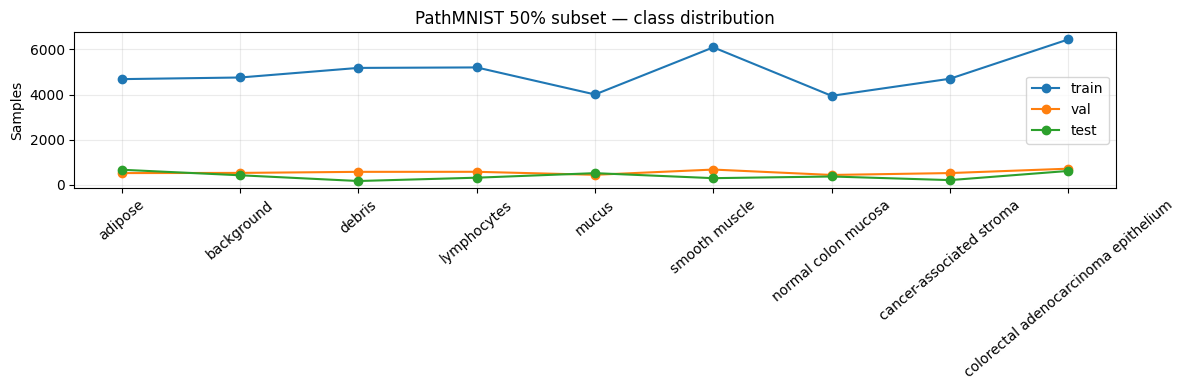

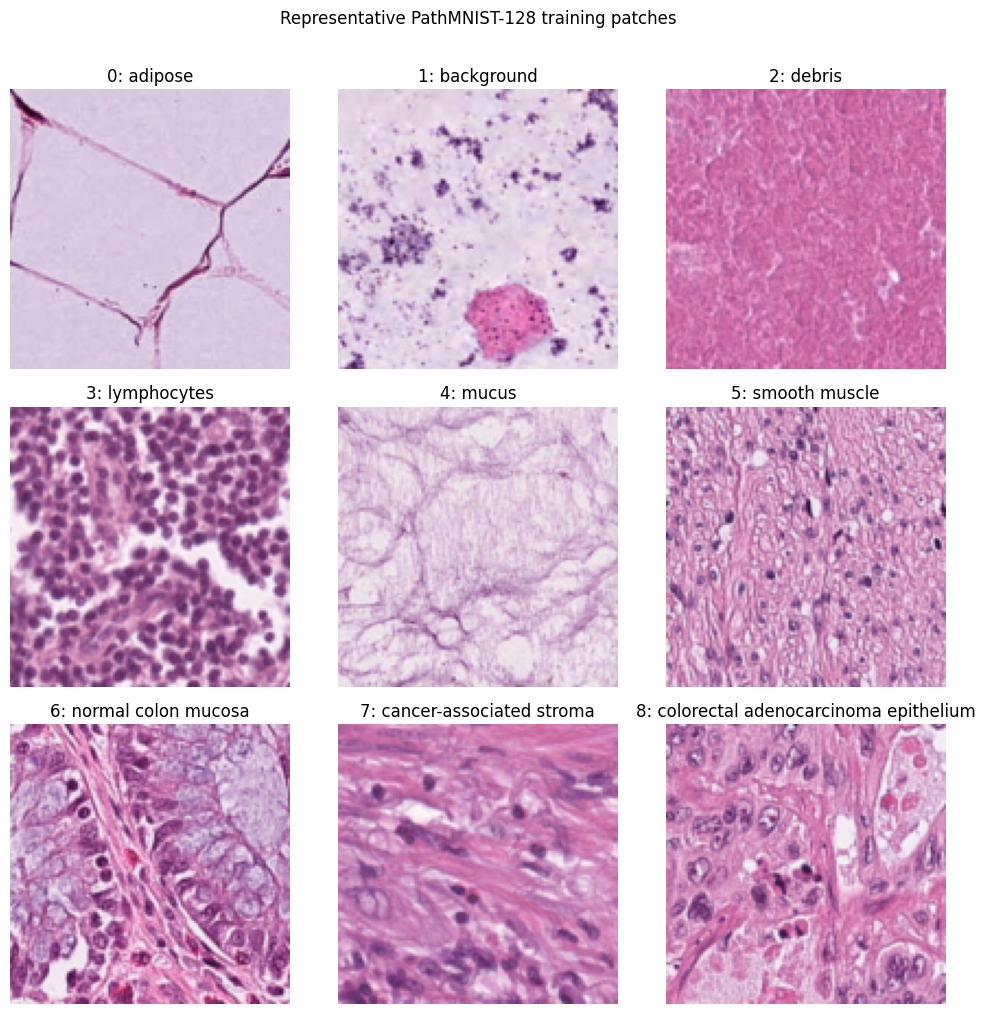

RGB EDA: train:   0%|          | 0/352 [00:00<?, ?it/s]

RGB EDA: val:   0%|          | 0/40 [00:00<?, ?it/s]

RGB EDA: test:   0%|          | 0/29 [00:00<?, ?it/s]

In [13]:
# Class counts in each official split and the validation sub-roles.
count_rows = []
for split, labels in [("train", TRAIN_LABELS), ("val", VAL_LABELS), ("test", TEST_LABELS)]:
    for cls in range(9):
        count_rows.append({"split": split, "class_id": cls, "class_name": CLASS_NAMES[cls], "count": int(np.sum(labels == cls))})
class_counts_df = pd.DataFrame(count_rows)
atomic_csv_save(class_counts_df, DIRS["logs"] / "eda_class_distribution.csv")

display(class_counts_df.pivot(index="class_name", columns="split", values="count"))

fig, ax = plt.subplots(figsize=(12, 4))
for split in ["train", "val", "test"]:
    tmp = class_counts_df[class_counts_df.split == split]
    ax.plot(tmp.class_name, tmp["count"], marker="o", label=split)
ax.set_title("PathMNIST 50% subset — class distribution")
ax.set_ylabel("Samples")
ax.tick_params(axis="x", rotation=40)
ax.legend(); ax.grid(alpha=.25); plt.tight_layout()
fig.savefig(DIRS["figures"] / "eda_class_distribution.png", dpi=160)
plt.show()

# Nine-class image montage from the training subset.
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
rng = np.random.default_rng(SEED)
for cls, ax in enumerate(axes.ravel()):
    choices = np.flatnonzero(TRAIN_LABELS == cls)
    idx = int(rng.choice(choices))
    ax.imshow(TRAIN_IMAGES[idx])
    ax.set_title(f"{cls}: {CLASS_NAMES[cls]}")
    ax.axis("off")
plt.suptitle("Representative PathMNIST-128 training patches", y=1.01)
plt.tight_layout()
plt.savefig(DIRS["figures"] / "eda_class_montage.png", dpi=160, bbox_inches="tight")
plt.show()

# Compute per-image RGB summaries in batches to avoid building a huge float copy.
def rgb_summary_for_split(images, split_name, batch_size=128):
    rows = []
    for start in tqdm(range(0, len(images), batch_size), desc=f"RGB EDA: {split_name}"):
        batch = images[start:start+batch_size].astype(np.float32) / 255.0
        means = batch.mean(axis=(1,2))
        stds = batch.std(axis=(1,2))
        lum = 0.2126*batch[...,0] + 0.7152*batch[...,1] + 0.0722*batch[...,2]
        brightness = lum.mean(axis=(1,2))
        contrast = lum.std(axis=(1,2))
        white = ((batch[...,0] > 0.90) & (batch[...,1] > 0.90) & (batch[...,2] > 0.90)).mean(axis=(1,2))
        for j in range(len(batch)):
            rows.append({
                "split": split_name,
                "position": start+j,
                "r_mean": means[j,0], "g_mean": means[j,1], "b_mean": means[j,2],
                "r_std": stds[j,0], "g_std": stds[j,1], "b_std": stds[j,2],
                "brightness_mean": brightness[j], "luminance_std": contrast[j],
                "near_white_fraction": white[j],
            })
    return pd.DataFrame(rows)

rgb_eda = pd.concat([
    rgb_summary_for_split(TRAIN_IMAGES, "train"),
    rgb_summary_for_split(VAL_IMAGES, "val"),
    rgb_summary_for_split(TEST_IMAGES, "test"),
], ignore_index=True)
# Attach class labels in the same order as the split arrays.
labels_concat = np.concatenate([TRAIN_LABELS, VAL_LABELS, TEST_LABELS])
rgb_eda["label"] = labels_concat
rgb_eda["class_name"] = [CLASS_NAMES[int(x)] for x in labels_concat]

H&E / texture / sharpness EDA:   0%|          | 0/360 [00:00<?, ?it/s]

C:\Users\saibh\AppData\Local\Temp\ipykernel_15892\1502964345.py:57: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[2].boxplot([quality_df.loc[quality_df.class_name==c,"laplacian_variance"] for c in CLASS_NAMES], labels=[c[:5] for c in CLASS_NAMES])


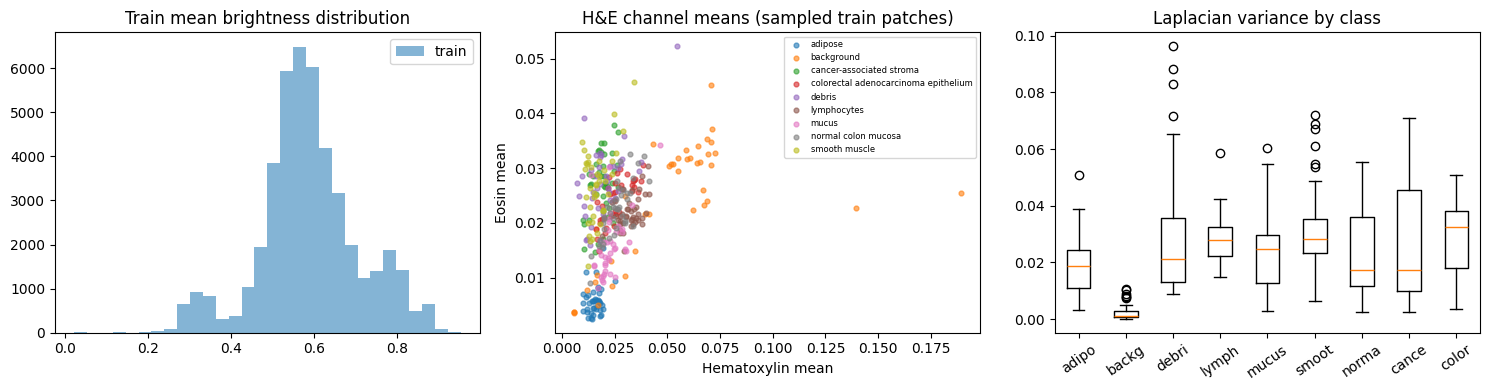

EDA files saved under: C:\Users\saibh\Videos\CV_MODEL\PathoLens_Workspace_50pct\logs


In [14]:
# Sharpness, H&E channel and texture descriptors on a reproducible class-balanced sample of training patches.
eda_rng = np.random.default_rng(SEED + 900)
selected_eda_indices = []
for cls in range(9):
    ids = np.flatnonzero(TRAIN_LABELS == cls)
    n = min(EDA_TEXTURE_PER_CLASS, len(ids))
    selected_eda_indices.extend(eda_rng.choice(ids, size=n, replace=False).tolist())
selected_eda_indices = sorted(selected_eda_indices)

texture_rows = []
quality_rows = []
stain_rows = []
for idx in tqdm(selected_eda_indices, desc="H&E / texture / sharpness EDA"):
    img = TRAIN_IMAGES[idx]
    gray = rgb2gray(img)
    sharpness = float(np.var(laplace(gray)))
    quality_rows.append({"split": "train", "position": int(idx), "label": int(TRAIN_LABELS[idx]), "class_name": CLASS_NAMES[int(TRAIN_LABELS[idx])], "laplacian_variance": sharpness})

    hed = rgb2hed(img.astype(np.float32) / 255.0)
    stain_rows.append({
        "split": "train", "position": int(idx), "label": int(TRAIN_LABELS[idx]),
        "class_name": CLASS_NAMES[int(TRAIN_LABELS[idx])],
        "hematoxylin_mean": float(hed[...,0].mean()), "hematoxylin_std": float(hed[...,0].std()),
        "eosin_mean": float(hed[...,1].mean()), "eosin_std": float(hed[...,1].std()),
    })

    gray_u8 = np.clip(gray * 31, 0, 31).astype(np.uint8)
    glcm = graycomatrix(gray_u8, distances=[1,2], angles=[0, np.pi/4, np.pi/2, 3*np.pi/4], levels=32, symmetric=True, normed=True)
    lbp = local_binary_pattern((gray*255).astype(np.uint8), P=8, R=1, method="uniform")
    hist, _ = np.histogram(lbp.ravel(), bins=np.arange(0, 12), density=True)
    texture_rows.append({
        "position": int(idx), "label": int(TRAIN_LABELS[idx]), "class_name": CLASS_NAMES[int(TRAIN_LABELS[idx])],
        "glcm_contrast": float(graycoprops(glcm, "contrast").mean()),
        "glcm_homogeneity": float(graycoprops(glcm, "homogeneity").mean()),
        "glcm_energy": float(graycoprops(glcm, "energy").mean()),
        "glcm_correlation": float(graycoprops(glcm, "correlation").mean()),
        "lbp_entropy": float(-(hist[hist>0] * np.log2(hist[hist>0])).sum()),
    })

quality_df = pd.DataFrame(quality_rows)
stain_df = pd.DataFrame(stain_rows)
texture_df = pd.DataFrame(texture_rows)
atomic_csv_save(rgb_eda, DIRS["logs"] / "eda_rgb_features.csv")
atomic_csv_save(quality_df, DIRS["logs"] / "eda_image_quality_sample.csv")
atomic_csv_save(stain_df, DIRS["logs"] / "eda_hed_stain_sample.csv")
atomic_csv_save(texture_df, DIRS["logs"] / "eda_texture_sample.csv")

# Summary plots: colour distributions, H&E descriptor distribution, and blur proxy.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sub = rgb_eda[rgb_eda.split == "train"]
axes[0].hist(sub["brightness_mean"], bins=30, alpha=.55, label="train")
axes[0].set_title("Train mean brightness distribution"); axes[0].legend()
for cls, sub in stain_df.groupby("class_name"):
    axes[1].scatter(sub["hematoxylin_mean"], sub["eosin_mean"], s=12, alpha=.6, label=cls)
axes[1].set_title("H&E channel means (sampled train patches)")
axes[1].set_xlabel("Hematoxylin mean"); axes[1].set_ylabel("Eosin mean"); axes[1].legend(fontsize=6)
axes[2].boxplot([quality_df.loc[quality_df.class_name==c,"laplacian_variance"] for c in CLASS_NAMES], labels=[c[:5] for c in CLASS_NAMES])
axes[2].set_title("Laplacian variance by class"); axes[2].tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.savefig(DIRS["figures"] / "eda_colour_stain_quality.png", dpi=160); plt.show()

print("EDA files saved under:", DIRS["logs"])

## 7. Macenko stain-normalized data variant (Experiment 3)

The reference stain matrix and reference concentration percentiles are estimated from a deterministic sample of **training-subset images only**. The fitted reference is saved. Each patch is then normalized independently with that fixed reference; labels are not used during normalization. Per-split cache files allow a completed split to be reused after a runtime restart.

Macenko normalization can fail on mostly blank / low-stain patches. Those samples are retained unchanged and counted in the cache metadata; no samples are silently dropped.

In [15]:
def estimate_macenko_parameters(rgb_u8, beta=MACENKO_BETA, alpha=MACENKO_ALPHA):
    img = np.asarray(rgb_u8, dtype=np.float64)
    if img.max() <= 1.0:
        img = img * 255.0
    od = -np.log((img.reshape(-1, 3) + 1.0) / 256.0)
    odhat = od[(od > beta).all(axis=1)]
    if odhat.shape[0] < 64:
        return None
    cov = np.cov(odhat, rowvar=False)
    eigvals, eigvecs = np.linalg.eigh(cov)
    order = np.argsort(eigvals)[::-1]
    v1, v2 = eigvecs[:, order[0]], eigvecs[:, order[1]]
    proj1, proj2 = odhat @ v1, odhat @ v2
    phi = np.arctan2(proj2, proj1)
    phi_min, phi_max = np.percentile(phi, [alpha, 100.0-alpha])
    s1 = v1*np.cos(phi_min) + v2*np.sin(phi_min)
    s2 = v1*np.cos(phi_max) + v2*np.sin(phi_max)
    W = np.column_stack([s1, s2])
    for j in range(2):
        if W[0, j] < 0:
            W[:, j] *= -1
    # Hematoxylin normally has the larger red-channel contribution than eosin.
    if W[0, 0] < W[0, 1]:
        W = W[:, [1, 0]]
    W = W / (np.linalg.norm(W, axis=0, keepdims=True) + 1e-8)
    C = od @ np.linalg.pinv(W).T
    C = np.clip(C, 0, None)
    maxC = np.percentile(C, 99.0, axis=0)
    if not np.isfinite(W).all() or not np.isfinite(maxC).all() or np.any(maxC < 1e-5):
        return None
    return W.astype(np.float32), maxC.astype(np.float32)

def fit_macenko_reference(train_images, n_reference=MACENKO_REFERENCE_IMAGES, seed=SEED):
    rng = np.random.default_rng(seed + 707)
    n = min(n_reference, len(train_images))
    ids = rng.choice(len(train_images), size=n, replace=False)
    Ws, maxCs = [], []
    for idx in tqdm(ids, desc="Fit Macenko reference from TRAIN only"):
        result = estimate_macenko_parameters(train_images[int(idx)])
        if result is not None:
            W, maxC = result
            Ws.append(W); maxCs.append(maxC)
    if len(Ws) < max(5, n // 10):
        raise RuntimeError("Too few training images produced valid stain estimates; cannot fit a stable Macenko reference.")
    W_ref = np.median(np.stack(Ws), axis=0)
    for j in range(2):
        W_ref[:,j] /= (np.linalg.norm(W_ref[:,j]) + 1e-8)
    if W_ref[0,0] < W_ref[0,1]:
        W_ref = W_ref[:,[1,0]]
    maxC_ref = np.median(np.stack(maxCs), axis=0)
    return W_ref.astype(np.float32), maxC_ref.astype(np.float32), {"reference_images_requested": int(n), "reference_images_used": int(len(Ws))}

def macenko_normalize(rgb_u8, W_ref, maxC_ref):
    img = np.asarray(rgb_u8, dtype=np.float64)
    od = -np.log((img.reshape(-1, 3) + 1.0) / 256.0)
    source = estimate_macenko_parameters(rgb_u8)
    if source is None:
        return np.asarray(rgb_u8, dtype=np.uint8), False
    W_src, _ = source
    C = od @ np.linalg.pinv(W_src).T
    C = np.clip(C, 0, None)
    maxC_src = np.percentile(C, 99.0, axis=0)
    maxC_src = np.maximum(maxC_src, 1e-5)
    C_norm = C * (maxC_ref / maxC_src)[None, :]
    od_norm = C_norm @ W_ref.T
    normalized = 256.0 * np.exp(-od_norm) - 1.0
    normalized = np.clip(normalized, 0, 255).reshape(rgb_u8.shape).astype(np.uint8)
    return normalized, True

MACENKO_META_PATH = DIRS["derived"] / "macenko_reference.json"
if MACENKO_META_PATH.exists():
    mac_meta = json.loads(MACENKO_META_PATH.read_text())
    if mac_meta.get("subset_sha256") != SUBSET_SHA or mac_meta.get("manifest_sha256") != MANIFEST_SHA:
        raise RuntimeError("Macenko reference belongs to a different subset/manifest. Use a clean workspace.")
    W_REF = np.asarray(mac_meta["W_ref"], dtype=np.float32)
    MAXC_REF = np.asarray(mac_meta["maxC_ref"], dtype=np.float32)
    print("Loaded saved Macenko reference.")
else:
    W_REF, MAXC_REF, fit_info = fit_macenko_reference(TRAIN_IMAGES)
    mac_meta = {
        "created_utc": datetime.now(timezone.utc).isoformat(),
        "subset_sha256": SUBSET_SHA,
        "manifest_sha256": MANIFEST_SHA,
        "W_ref": W_REF.tolist(),
        "maxC_ref": MAXC_REF.tolist(),
        **fit_info,
        "method": "Macenko optical-density stain normalization; reference estimated from train subset only",
    }
    atomic_json_save(mac_meta, MACENKO_META_PATH)

print("Reference stain matrix:\n", W_REF)
print("Reference concentration percentiles:", MAXC_REF)

Fit Macenko reference from TRAIN only:   0%|          | 0/128 [00:00<?, ?it/s]

Reference stain matrix:
 [[0.46167675 0.42296562]
 [0.7824579  0.7971021 ]
 [0.41786867 0.43096212]]
Reference concentration percentiles: [2.0931842 9.196749 ]


In [16]:
def ensure_macenko_cache(split, images):
    cache_path = DIRS["derived"] / f"macenko_{split}.npy"
    status_path = DIRS["derived"] / f"macenko_{split}_status.json"
    expected_shape = tuple(images.shape)
    if cache_path.exists() and status_path.exists():
        status = json.loads(status_path.read_text(encoding="utf-8"))
        if status.get("subset_sha256") == SUBSET_SHA and tuple(status.get("shape", [])) == expected_shape:
            print(f"Reusing Macenko disk cache: {split}")
            return np.load(cache_path, mmap_mode="r", allow_pickle=False), int(status["fallback_count"])
        cache_path.unlink(missing_ok=True)
        status_path.unlink(missing_ok=True)

    out_mm = np.lib.format.open_memmap(
        cache_path, mode="w+", dtype=np.uint8, shape=expected_shape)
    fallback_count = 0
    for i in tqdm(range(len(images)), desc=f"Macenko normalize: {split}"):
        out, ok = macenko_normalize(np.asarray(images[i]), W_REF, MAXC_REF)
        out_mm[i] = out
        fallback_count += int(not ok)
        if (i + 1) % 2000 == 0:
            out_mm.flush()
    out_mm.flush()
    del out_mm
    atomic_json_save({
        "split": split, "subset_sha256": SUBSET_SHA,
        "shape": list(expected_shape), "fallback_count": int(fallback_count),
        "storage": "disk-backed .npy memmap",
    }, status_path)
    return np.load(cache_path, mmap_mode="r", allow_pickle=False), fallback_count

MACENKO_IMAGES, mac_fallbacks = {}, {}
for split, images in (("train", TRAIN_IMAGES), ("val", VAL_IMAGES), ("test", TEST_IMAGES)):
    MACENKO_IMAGES[split], mac_fallbacks[split] = ensure_macenko_cache(split, images)
macenko_status = pd.DataFrame([
    {"split": k, "samples": len(MACENKO_IMAGES[k]), "fallback_unchanged": mac_fallbacks[k]}
    for k in MACENKO_IMAGES
])
atomic_csv_save(macenko_status, DIRS["logs"] / "macenko_preprocessing_status.csv")
display(macenko_status)
MACENKO_REFERENCE_SHA = sha256_file(MACENKO_META_PATH)
MACENKO_CACHE_SHA = sha256_json({
    split: sha256_file(DIRS["derived"] / f"macenko_{split}.npy")
    for split in ("train", "val", "test")
})
print("Macenko reference hash:", MACENKO_REFERENCE_SHA)
print("Macenko cache fingerprint:", MACENKO_CACHE_SHA)

Macenko normalize: train:   0%|          | 0/44998 [00:00<?, ?it/s]

Macenko normalize: val:   0%|          | 0/5002 [00:00<?, ?it/s]

Macenko normalize: test:   0%|          | 0/3590 [00:00<?, ?it/s]

,split,samples,fallback_unchanged
0,train,44998,627
1,val,5002,68
2,test,3590,24


Macenko reference hash: dd63100f9681d36a994bfa99e97c50c6a498cfc5b8f475e369475913361e70da
Macenko cache fingerprint: 5ed261b78970c3d44c5df09b40b96c7e6f5894d3da5c4466e24c037abcbc0368


## 8. Shared image transforms and PyTorch datasets

E1/E3/E4 use identical geometric training augmentation. E2 adds controlled H&E-channel perturbation in HED space. Validation and test transforms are deterministic. All inputs use the same ImageNet normalization because the backbone starts from ImageNet-pretrained weights.

In [17]:
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)

class RandomRotate90:
    def __call__(self, img):
        k = int(torch.randint(0, 4, (1,)).item())
        return img.rotate(90 * k)

class HEDStainPerturb:
    """Small H/E optical-density perturbations; DAB channel is left unchanged."""
    def __init__(self, p=0.65, h_scale=(0.88,1.12), e_scale=(0.88,1.12), h_shift=(-0.025,0.025), e_shift=(-0.025,0.025)):
        self.p = p
        self.h_scale, self.e_scale = h_scale, e_scale
        self.h_shift, self.e_shift = h_shift, e_shift
    def __call__(self, img):
        if torch.rand(1).item() > self.p:
            return img
        arr = np.asarray(img.convert("RGB"), dtype=np.float32) / 255.0
        hed = rgb2hed(arr)
        hs = float(torch.empty(1).uniform_(*self.h_scale).item())
        es = float(torch.empty(1).uniform_(*self.e_scale).item())
        ho = float(torch.empty(1).uniform_(*self.h_shift).item())
        eo = float(torch.empty(1).uniform_(*self.e_shift).item())
        hed[...,0] = hed[...,0] * hs + ho
        hed[...,1] = hed[...,1] * es + eo
        out = np.clip(hed2rgb(hed), 0, 1)
        return Image.fromarray((out * 255.0).round().astype(np.uint8))

BASE_TRAIN_TRANSFORM = transforms.Compose([
    RandomRotate90(),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
HED_TRAIN_TRANSFORM = transforms.Compose([
    RandomRotate90(),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    HEDStainPerturb(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
EVAL_TRANSFORM = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class PathSubsetDataset(torch.utils.data.Dataset):
    def __init__(self, images, labels, transform):
        self.images = images
        self.labels = np.asarray(labels, dtype=np.int64).reshape(-1)
        self.transform = transform
        assert len(self.images) == len(self.labels)
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, idx):
        image = Image.fromarray(self.images[idx]).convert("RGB")
        x = self.transform(image)
        return x, int(self.labels[idx]), int(idx)

VAL_SELECT_IMAGES = VAL_IMAGES[VAL_SELECT_POS]
VAL_SELECT_LABELS = VAL_LABELS[VAL_SELECT_POS]
VAL_CALIB_IMAGES = VAL_IMAGES[VAL_CALIB_POS]
VAL_CALIB_LABELS = VAL_LABELS[VAL_CALIB_POS]

# Class weights are based on the selected TRAIN labels only and reused across all experiments.
train_counts = np.bincount(TRAIN_LABELS, minlength=9).astype(np.float64)
imbalance_ratio = float(train_counts.max() / max(train_counts.min(), 1))
if AUTO_CLASS_WEIGHTS and imbalance_ratio >= CLASS_WEIGHT_IMBALANCE_THRESHOLD:
    class_weights_np = (train_counts.mean() / train_counts) ** CLASS_WEIGHT_POWER
    class_weights_np = class_weights_np / class_weights_np.mean()
else:
    class_weights_np = np.ones(9, dtype=np.float32)
    if AUTO_CLASS_WEIGHTS:
        print(f"Class imbalance ratio={imbalance_ratio:.3f}; below threshold. Using unweighted cross-entropy.")
CLASS_WEIGHTS = torch.tensor(class_weights_np, dtype=torch.float32, device=DEVICE)
print("Train counts:", train_counts.astype(int).tolist())
print("Class weights:", class_weights_np.round(3).tolist())

Train counts: [4683, 4755, 5180, 5201, 4003, 6091, 3943, 4700, 6442]
Class weights: [1.024, 1.016, 0.973, 0.971, 1.107, 0.898, 1.116, 1.022, 0.873]


## 9. Model definitions — compact MobileNetV3-Small and multi-scale variant

The baseline retains the pretrained MobileNetV3-Small feature extractor. Its ImageNet classifier is replaced with a compact nine-class head containing LayerNorm and dropout. The convolutional backbone retains its pretrained BatchNorm layers; their running statistics are held in evaluation mode during fine-tuning to avoid noisy updates from the small subset.

E4 taps three feature stages, globally pools each stage, concatenates the resulting vector, and uses a small LayerNorm-based head. The notebook prints the actual parameter count and verifies feature dimensions with a dummy forward pass.

In [18]:
PRETRAINED_PATH = DIRS["pretrained"] / "mobilenet_v3_small_imagenet1k_v1_state_dict.pt"
LOCAL_PRETRAINED_PATH = PRETRAINED_PATH

if PRETRAINED_PATH.exists():
    if (not LOCAL_PRETRAINED_PATH.exists()) or (sha256_file(LOCAL_PRETRAINED_PATH) != sha256_file(PRETRAINED_PATH)):
        shutil.copy2(PRETRAINED_PATH, LOCAL_PRETRAINED_PATH)
    PRETRAINED_STATE = read_state_dict(LOCAL_PRETRAINED_PATH)
    print("Loaded saved ImageNet initialization.")
else:
    print("Downloading official Torchvision MobileNetV3-Small ImageNet weights once...")
    base_pretrained = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)
    PRETRAINED_STATE = {k: v.detach().cpu() for k, v in base_pretrained.state_dict().items()}
    atomic_torch_save(PRETRAINED_STATE, LOCAL_PRETRAINED_PATH)
    # Saved directly to the local workspace.
    del base_pretrained
    print("Saved pretrained initialization to the local workspace.")

PRETRAINED_SHA = sha256_file(PRETRAINED_PATH)

class MobileNetV3SmallClassifier(nn.Module):
    model_id = "mobilenet_v3_small_compact_head_v1"
    def __init__(self, pretrained_state):
        super().__init__()
        self.backbone = models.mobilenet_v3_small(weights=None)
        self.backbone.load_state_dict(pretrained_state, strict=True)
        in_features = self.backbone.classifier[0].in_features  # 576 for MobileNetV3-Small
        self.backbone.classifier = nn.Sequential(
            nn.Linear(in_features, 192, bias=False),
            nn.LayerNorm(192),
            nn.Hardswish(),
            nn.Dropout(p=0.25),
            nn.Linear(192, 9),
        )
    def forward(self, x):
        return self.backbone(x)
    def extract_embedding(self, x):
        x = self.backbone.features(x)
        x = self.backbone.avgpool(x)
        return torch.flatten(x, 1)
    @property
    def cam_layer(self):
        return self.backbone.features[-1]
    @property
    def head_module(self):
        return self.backbone.classifier
    @property
    def backbone_module(self):
        return self.backbone.features

class MultiScaleMobileNetV3Small(nn.Module):
    model_id = "mobilenet_v3_small_multiscale_head_v1"
    def __init__(self, pretrained_state):
        super().__init__()
        self.backbone = models.mobilenet_v3_small(weights=None)
        self.backbone.load_state_dict(pretrained_state, strict=True)
        self.backbone.classifier = nn.Identity()
        self.tap_indices = (3, 6, 12)  # intermediate, intermediate, final feature stages
        # Infer channel dimensions rather than hard-coding them.
        with torch.no_grad():
            x = torch.zeros(1, 3, IMAGE_SIZE, IMAGE_SIZE)
            dims = []
            for idx, layer in enumerate(self.backbone.features):
                x = layer(x)
                if idx in self.tap_indices:
                    dims.append(int(x.shape[1]))
        self.feature_dims = tuple(dims)
        total_dim = sum(dims)
        self.head = nn.Sequential(
            nn.LayerNorm(total_dim),
            nn.Linear(total_dim, 160, bias=False),
            nn.LayerNorm(160),
            nn.Hardswish(),
            nn.Dropout(p=0.25),
            nn.Linear(160, 9),
        )
    def extract_embedding(self, x):
        pooled = []
        for idx, layer in enumerate(self.backbone.features):
            x = layer(x)
            if idx in self.tap_indices:
                pooled.append(F.adaptive_avg_pool2d(x, 1).flatten(1))
        return torch.cat(pooled, dim=1)
    def forward(self, x):
        return self.head(self.extract_embedding(x))
    @property
    def cam_layer(self):
        return self.backbone.features[-1]
    @property
    def head_module(self):
        return self.head
    @property
    def backbone_module(self):
        return self.backbone.features

def build_model(experiment_id, seed=SEED):
    seed_everything(seed)
    if experiment_id == "E4":
        return MultiScaleMobileNetV3Small(PRETRAINED_STATE)
    return MobileNetV3SmallClassifier(PRETRAINED_STATE)

for exp_id in ["E1", "E4"]:
    model = build_model(exp_id).to(DEVICE)
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(exp_id, type(model).__name__, "trainable parameters:", f"{n_params:,}", "feature dims:", getattr(model, "feature_dims", None))
    with torch.no_grad():
        out = model(torch.zeros(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=DEVICE))
    assert out.shape == (2, 9), out.shape
    del model, out

Saved pretrained initialization to the local workspace.
E1 MobileNetV3SmallClassifier trainable parameters: 1,039,721 feature dims: None
E4 MultiScaleMobileNetV3Small trainable parameters: 1,032,457 feature dims: (24, 40, 576)


## 10. Metric, scheduler, RNG, checkpoint, and experiment-status utilities

The checkpoint contains model weights, optimizer, scheduler, AMP scaler, epoch number, best score, early-stopping counter, RNG states, manifest/data hashes, and the last completed epoch's metric row. CSV writing is idempotent so a crash between checkpoint saving and CSV update can be reconciled without duplicate rows.

In [19]:
EPOCH_METRICS_PATH = DIRS["logs"] / "epoch_metrics.csv"
EXPERIMENT_STATUS_PATH = DIRS["logs"] / "experiment_status.csv"


def expected_calibration_error(y_true, probs, n_bins=15):
    y_true = np.asarray(y_true).astype(int)
    probs = np.asarray(probs, dtype=np.float64)
    confidences = probs.max(axis=1)
    predictions = probs.argmax(axis=1)
    correctness = (predictions == y_true).astype(float)
    edges = np.linspace(0.0, 1.0, n_bins+1)
    ece = 0.0
    for i in range(n_bins):
        if i == n_bins-1:
            mask = (confidences >= edges[i]) & (confidences <= edges[i+1])
        else:
            mask = (confidences >= edges[i]) & (confidences < edges[i+1])
        if mask.any():
            ece += mask.mean() * abs(correctness[mask].mean() - confidences[mask].mean())
    return float(ece)

def compute_classification_metrics(y_true, logits_or_probs, input_is_probs=False):
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(logits_or_probs, dtype=np.float64)
    if input_is_probs:
        probs = np.clip(scores, 1e-9, 1.0)
        probs = probs / probs.sum(axis=1, keepdims=True)
    else:
        shifted = scores - scores.max(axis=1, keepdims=True)
        ex = np.exp(shifted)
        probs = ex / ex.sum(axis=1, keepdims=True)
    pred = probs.argmax(axis=1)
    y_oh = np.eye(9)[y_true]
    cm = confusion_matrix(y_true, pred, labels=np.arange(9))
    specificity = []
    for c in range(9):
        tp = cm[c,c]; fn = cm[c,:].sum()-tp; fp = cm[:,c].sum()-tp
        tn = cm.sum()-tp-fn-fp
        specificity.append(tn / max(tn+fp, 1))
    try:
        macro_auc = roc_auc_score(y_true, probs, multi_class="ovr", average="macro", labels=np.arange(9))
    except Exception:
        macro_auc = np.nan
    try:
        macro_ap = average_precision_score(y_oh, probs, average="macro")
    except Exception:
        macro_ap = np.nan
    return {
        "accuracy": float(accuracy_score(y_true, pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, pred)),
        "macro_precision": float(precision_score(y_true, pred, average="macro", zero_division=0)),
        "macro_recall": float(recall_score(y_true, pred, average="macro", zero_division=0)),
        "macro_f1": float(f1_score(y_true, pred, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, pred, average="weighted", zero_division=0)),
        "macro_specificity": float(np.mean(specificity)),
        "top2_accuracy": float(np.any(np.argpartition(probs, -2, axis=1)[:, -2:] == y_true[:, None], axis=1).mean()),
        "mcc": float(matthews_corrcoef(y_true, pred)),
        "cohen_kappa": float(cohen_kappa_score(y_true, pred)),
        "nll": float(log_loss(y_true, probs, labels=np.arange(9))),
        "brier_score": float(np.mean(np.sum((probs-y_oh)**2, axis=1))),
        "ece_15bins": expected_calibration_error(y_true, probs, n_bins=15),
        "macro_ovr_auc": float(macro_auc) if np.isfinite(macro_auc) else np.nan,
        "macro_average_precision": float(macro_ap) if np.isfinite(macro_ap) else np.nan,
        "n_samples": int(len(y_true)),
    }

def compute_per_class_metrics(y_true, probs, experiment_id, split_name):
    y_true = np.asarray(y_true).astype(int)
    pred = np.asarray(probs).argmax(axis=1)
    cm = confusion_matrix(y_true, pred, labels=np.arange(9))
    rows = []
    for c in range(9):
        tp = cm[c,c]; fn = cm[c,:].sum()-tp; fp = cm[:,c].sum()-tp
        tn = cm.sum()-tp-fn-fp
        rows.append({
            "experiment_id": experiment_id, "split": split_name,
            "class_id": c, "class_name": CLASS_NAMES[c],
            "support": int(cm[c,:].sum()),
            "precision": float(tp/max(tp+fp,1)),
            "recall": float(tp/max(tp+fn,1)),
            "specificity": float(tn/max(tn+fp,1)),
            "f1": float(2*tp/max(2*tp+fp+fn,1)),
        })
    return rows

def get_rng_state():
    state = {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch_cpu": torch.get_rng_state(),
    }
    if torch.cuda.is_available():
        state["torch_cuda"] = torch.cuda.get_rng_state_all()
    return state

def set_rng_state(state):
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch_cpu"])
    if torch.cuda.is_available() and "torch_cuda" in state:
        try:
            torch.cuda.set_rng_state_all(state["torch_cuda"])
        except Exception as exc:
            # Cross-device/backend RNG state may not be portable. Continue with a seeded CUDA RNG;
            # the checkpoint still restores weights/optimizer/scheduler, but exact replay is not promised.
            warnings.warn(f"Could not restore saved CUDA RNG state ({exc}); reseeding CUDA RNG instead.")
            torch.cuda.manual_seed_all(SEED)

def make_scheduler(optimizer):
    # Linear warm-up followed by cosine decay; scheduler state is checkpointed.
    def lr_lambda(epoch):
        if epoch < WARMUP_EPOCHS:
            return float(epoch + 1) / max(1, WARMUP_EPOCHS)
        progress = (epoch - WARMUP_EPOCHS) / max(1, EPOCHS - WARMUP_EPOCHS)
        return 0.05 + 0.95 * 0.5 * (1.0 + math.cos(math.pi * min(progress, 1.0)))
    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lr_lambda)

def update_csv_row(path, row, key_cols):
    path = Path(path)
    if path.exists():
        df = pd.read_csv(path)
        if len(df):
            mask = np.ones(len(df), dtype=bool)
            for col in key_cols:
                mask &= df[col].astype(str).to_numpy() == str(row[col])
            df = df.loc[~mask]
        df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
    else:
        df = pd.DataFrame([row])
    sort_cols = [c for c in ["experiment_id", "epoch"] if c in df.columns]
    if sort_cols:
        df = df.sort_values(sort_cols).reset_index(drop=True)
    atomic_csv_save(df, path)
    return df

def update_status(experiment_id, status, last_epoch=0, best_epoch=None, best_macro_f1=None, message=""):
    row = {
        "experiment_id": experiment_id, "status": status,
        "last_completed_epoch": int(last_epoch),
        "best_epoch": int(best_epoch) if best_epoch is not None else np.nan,
        "best_val_macro_f1": float(best_macro_f1) if best_macro_f1 is not None else np.nan,
        "updated_utc": datetime.now(timezone.utc).isoformat(),
        "message": str(message)[:1000],
    }
    return update_csv_row(EXPERIMENT_STATUS_PATH, row, ["experiment_id"])


def save_persistent_artifact(local_path, persistent_path):
    mirror_file(local_path, persistent_path)


def resume_signature(experiment_id, model_id, recipe):
    # Hardware-specific settings (device, AMP, worker count) are deliberately excluded
    # so a saved run can move between Colab and a local laptop.
    return sha256_json({
        "notebook_version": NOTEBOOK_VERSION,
        "experiment_id": experiment_id,
        "model_id": model_id,
        "recipe": recipe,
        "image_size": IMAGE_SIZE,
        "data_size": DATA_SIZE,
        "seed": SEED,
        "batch_size": BATCH_SIZE,
        "epochs": EPOCHS,
        "backbone_lr": BACKBONE_LR,
        "head_lr": HEAD_LR,
        "weight_decay": WEIGHT_DECAY,
        "label_smoothing": LABEL_SMOOTHING,
        "warmup_epochs": WARMUP_EPOCHS,
        "early_stopping_patience": EARLY_STOPPING_PATIENCE,
        "gradient_clip_norm": GRAD_CLIP_NORM,
        "class_weights": class_weights_np.round(8).tolist(),
        "pretrained_sha256": PRETRAINED_SHA,
        "subset_sha256": SUBSET_SHA,
        "manifest_sha256": MANIFEST_SHA,
        "macenko_reference_sha256": MACENKO_REFERENCE_SHA if experiment_id == "E3" else None,
        "macenko_cache_sha256": MACENKO_CACHE_SHA if experiment_id == "E3" else None,
    })

print("Training / checkpoint utilities ready.")

Training / checkpoint utilities ready.


## 11. GPU DataLoaders and training / evaluation loops

The model and batches are moved to `cuda:0`. CUDA mixed precision is enabled when available. The DataLoader uses pinned memory for faster host-to-GPU transfer; Windows defaults to `num_workers=0` for notebook stability. The train loader is recreated per epoch with an epoch-specific generator seed, making sample order reproducible at epoch boundaries.

In [20]:
EXPERIMENTS = {
    "E1": {"name": "RGB baseline", "model_id": MobileNetV3SmallClassifier.model_id, "recipe": "original_rgb + geometric_aug", "variant": "original", "train_transform": "base"},
    "E2": {"name": "HED stain augmentation", "model_id": MobileNetV3SmallClassifier.model_id, "recipe": "original_rgb + geometric_aug + hed_stain_perturb", "variant": "original", "train_transform": "hed"},
    "E3": {"name": "Macenko stain normalization", "model_id": MobileNetV3SmallClassifier.model_id, "recipe": "macenko_normalized + geometric_aug", "variant": "macenko", "train_transform": "base"},
    "E4": {"name": "Multi-scale MobileNetV3-Small", "model_id": MultiScaleMobileNetV3Small.model_id, "recipe": "original_rgb + multiscale_feature_fusion", "variant": "original", "train_transform": "base"},
}

def make_loaders(experiment_id, epoch):
    exp = EXPERIMENTS[experiment_id]
    if exp["variant"] == "macenko":
        tr_images = MACENKO_IMAGES["train"]
        va_images = MACENKO_IMAGES["val"][VAL_SELECT_POS]
    else:
        tr_images = TRAIN_IMAGES
        va_images = VAL_SELECT_IMAGES
    train_transform = HED_TRAIN_TRANSFORM if exp["train_transform"] == "hed" else BASE_TRAIN_TRANSFORM
    train_ds = PathSubsetDataset(tr_images, TRAIN_LABELS, train_transform)
    val_ds = PathSubsetDataset(va_images, VAL_SELECT_LABELS, EVAL_TRANSFORM)
    generator = torch.Generator()
    generator.manual_seed(SEED + (int(experiment_id[1:]) * 100003) + int(epoch) * 1009)
    train_loader = torch.utils.data.DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True,
        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type=="cuda"),
        persistent_workers=False, generator=generator, drop_last=False,
    )
    val_loader = torch.utils.data.DataLoader(
        val_ds, batch_size=BATCH_SIZE*2, shuffle=False,
        num_workers=NUM_WORKERS, pin_memory=(DEVICE.type=="cuda"),
        persistent_workers=False,
    )
    return train_loader, val_loader

def make_optimizer(model):
    backbone_params = list(model.backbone_module.parameters())
    head_params = list(model.head_module.parameters())
    optimizer = torch.optim.AdamW(
        [
            {"params": backbone_params, "lr": BACKBONE_LR, "name": "backbone"},
            {"params": head_params, "lr": HEAD_LR, "name": "head"},
        ], weight_decay=WEIGHT_DECAY
    )
    return optimizer

def freeze_batchnorm_running_stats(model):
    # Keep pretrained BatchNorm running statistics fixed; affine parameters remain trainable.
    for module in model.modules():
        if isinstance(module, (nn.BatchNorm1d, nn.BatchNorm2d, nn.BatchNorm3d)):
            module.eval()

def autocast_context():
    return torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP_ENABLED)

def make_grad_scaler():
    try:
        return torch.amp.GradScaler("cuda", enabled=AMP_ENABLED)
    except Exception:
        return torch.cuda.amp.GradScaler(enabled=AMP_ENABLED)

def run_train_epoch(model, loader, criterion, optimizer, scaler, experiment_id, epoch):
    model.train()
    freeze_batchnorm_running_stats(model)
    all_logits, all_y = [], []
    loss_sum, n_seen = 0.0, 0
    t0 = time.time()
    progress = tqdm(loader, desc=f"{experiment_id} | epoch {epoch+1}/{EPOCHS} | train", leave=False)
    for xb, yb, _ in progress:
        xb = xb.to(DEVICE, non_blocking=True)
        yb = yb.to(DEVICE, dtype=torch.long, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with autocast_context():
            logits = model(xb)
            loss = criterion(logits, yb)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
        scaler.step(optimizer)
        scaler.update()
        bs = int(yb.size(0))
        loss_sum += float(loss.detach().item()) * bs
        n_seen += bs
        all_logits.append(logits.detach().float().cpu().numpy())
        all_y.append(yb.detach().cpu().numpy())
        progress.set_postfix(loss=f"{loss_sum/max(n_seen,1):.4f}")
    elapsed = time.time() - t0
    logits_np = np.concatenate(all_logits)
    y_np = np.concatenate(all_y)
    train_metrics = compute_classification_metrics(y_np, logits_np)
    return loss_sum/max(n_seen,1), train_metrics, elapsed, n_seen

@torch.no_grad()
def run_eval_epoch(model, loader, criterion, desc="validation"):
    model.eval()
    all_logits, all_y = [], []
    loss_sum, n_seen = 0.0, 0
    for xb, yb, _ in tqdm(loader, desc=desc, leave=False):
        xb = xb.to(DEVICE, non_blocking=True)
        yb = yb.to(DEVICE, dtype=torch.long, non_blocking=True)
        with autocast_context():
            logits = model(xb)
            loss = criterion(logits, yb)
        bs = int(yb.size(0))
        loss_sum += float(loss.item()) * bs
        n_seen += bs
        all_logits.append(logits.float().cpu().numpy())
        all_y.append(yb.cpu().numpy())
    logits_np = np.concatenate(all_logits)
    y_np = np.concatenate(all_y)
    metrics = compute_classification_metrics(y_np, logits_np)
    return loss_sum/max(n_seen,1), metrics, logits_np, y_np

print("Training loops ready.")

Training loops ready.


## 12. Crash-safe local experiment runner

For each experiment:

- `best_model.pt` is the best validation-Macro-F1 model and is retained.
- `last_checkpoint.pt` is the rolling full-state checkpoint. It is written to a temporary file and atomically replaced only after an epoch completes.
- `epoch_metrics.csv` and `experiment_status.csv` are updated after each completed epoch.
- If the notebook/kernel/process stops mid-epoch, the previous completed epoch remains the recovery point; the interrupted epoch is repeated.
- The checkpoint contains model, optimizer, scheduler, AMP scaler, RNG state, epoch, best score, dataset/manifest hashes and experiment signature.
- The notebook refuses to resume if the dataset, pretrained weights, model recipe or core training configuration differs.

All files are written under `LOCAL_WORKSPACE_ROOT/experiments` and `LOCAL_WORKSPACE_ROOT/logs`.

In [21]:
def experiment_dirs(experiment_id):
    # Single canonical local folder: there is no local reconciliation.
    local = DIRS["experiments"] / experiment_id
    local.mkdir(parents=True, exist_ok=True)
    return local, local

def sync_experiment_csvs():
    # CSVs are already written to the canonical local workspace.
    return

def build_checkpoint_payload(model, optimizer, scheduler, scaler, epoch_completed,
                             best_score, best_epoch, no_improve, signature, last_metrics):
    return {
        "checkpoint_version": 1,
        "experiment_id": CURRENT_EXPERIMENT_ID,
        "model_id": EXPERIMENTS[CURRENT_EXPERIMENT_ID]["model_id"],
        "model_state_dict": {k: v.detach().cpu() for k,v in model.state_dict().items()},
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),
        "scaler_state_dict": scaler.state_dict(),
        "epoch_completed": int(epoch_completed),
        "best_val_macro_f1": float(best_score),
        "best_epoch": int(best_epoch),
        "no_improve_epochs": int(no_improve),
        "resume_signature": signature,
        "subset_sha256": SUBSET_SHA,
        "manifest_sha256": MANIFEST_SHA,
        "pretrained_sha256": PRETRAINED_SHA,
        "notebook_version": NOTEBOOK_VERSION,
        "last_metrics": last_metrics,
        "rng_state": get_rng_state(),
        "training_config": {
            "epochs": EPOCHS, "batch_size": BATCH_SIZE, "backbone_lr": BACKBONE_LR,
            "head_lr": HEAD_LR, "weight_decay": WEIGHT_DECAY,
            "label_smoothing": LABEL_SMOOTHING, "image_size": IMAGE_SIZE,
            "seed": SEED, "amp_enabled_on_saved_machine": AMP_ENABLED,
            "device_on_saved_machine": str(DEVICE), "num_workers_on_saved_machine": NUM_WORKERS,
        },
    }

def save_checkpoint_pair(payload, local_dir, persistent_dir, filename):
    local_path = local_dir / filename
    persistent_path = persistent_dir / filename
    atomic_torch_save(payload, local_path)
    # local_dir and persistent_dir resolve to the same local folder; save once.

def save_best_checkpoint(model, experiment_id, epoch, score, local_dir, persistent_dir):
    payload = {
        "checkpoint_version": 1,
        "experiment_id": experiment_id,
        "model_id": EXPERIMENTS[experiment_id]["model_id"],
        "model_state_dict": {k: v.detach().cpu() for k,v in model.state_dict().items()},
        "best_epoch": int(epoch),
        "best_val_macro_f1": float(score),
        "subset_sha256": SUBSET_SHA,
        "manifest_sha256": MANIFEST_SHA,
        "pretrained_sha256": PRETRAINED_SHA,
        "class_names": CLASS_NAMES,
        "image_size": IMAGE_SIZE,
        "experiment_recipe": EXPERIMENTS[experiment_id]["recipe"],
    }
    save_checkpoint_pair(payload, local_dir, persistent_dir, "best_model.pt")

def reconcile_epoch_csv(checkpoint):
    row = checkpoint.get("last_metrics")
    if row is not None:
        update_csv_row(EPOCH_METRICS_PATH, row, ["experiment_id", "epoch"])

def run_experiment(experiment_id):
    global CURRENT_EXPERIMENT_ID
    if experiment_id not in EXPERIMENTS:
        raise ValueError(experiment_id)
    CURRENT_EXPERIMENT_ID = experiment_id
    exp = EXPERIMENTS[experiment_id]
    local_dir, persistent_dir = experiment_dirs(experiment_id)
    best_path = persistent_dir / "best_model.pt"
    latest_path = persistent_dir / "last_checkpoint.pt"
    status_path = EXPERIMENT_STATUS_PATH

    # Reuse a saved best model whenever its dataset/model identity is valid.
    # This is deliberately independent of experiment_status.csv: a copied workspace
    # may contain valid checkpoints even if its status log was not copied.
    if REUSE_VALID_BEST_CHECKPOINTS and best_path.exists():
        try:
            existing_best = read_torch_checkpoint(best_path, map_location="cpu")
            expected_best = {
                "experiment_id": experiment_id,
                "model_id": exp["model_id"],
                "subset_sha256": SUBSET_SHA,
                "manifest_sha256": MANIFEST_SHA,
                "pretrained_sha256": PRETRAINED_SHA,
                "image_size": IMAGE_SIZE,
                "experiment_recipe": exp["recipe"],
            }
            mismatches = [k for k, v in expected_best.items() if existing_best.get(k) != v]
            if mismatches:
                raise RuntimeError(f"checkpoint metadata mismatch: {mismatches}")
            if "model_state_dict" not in existing_best:
                raise RuntimeError("checkpoint has no model_state_dict")
            # Strict loading verifies that the saved tensors match this exact model definition.
            probe_model = build_model(experiment_id).to(DEVICE)
            probe_model.load_state_dict(existing_best["model_state_dict"], strict=True)
            del probe_model
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()
            old_epoch = int(existing_best.get("best_epoch", 0))
            old_score = float(existing_best.get("best_val_macro_f1", np.nan))
            last_epoch = old_epoch
            if latest_path.exists():
                try:
                    latest_existing = read_torch_checkpoint(latest_path, map_location="cpu")
                    last_epoch = int(latest_existing.get("epoch_completed", last_epoch))
                except Exception:
                    pass
            update_status(experiment_id, "completed", last_epoch, old_epoch, old_score,
                          "Reused existing best_model.pt after strict architecture and dataset verification")
            print(f"{experiment_id}: reusing verified best_model.pt (best epoch={old_epoch}, val Macro-F1={old_score:.4f}); no retraining.")
            return
        except Exception as reuse_exc:
            warnings.warn(f"Cannot reuse {experiment_id} best checkpoint ({reuse_exc}). Will resume from a matching last_checkpoint.pt or train it.")

    # Do not trust a stale 'completed' status without a valid best checkpoint.
    # The normal resume-signature check below decides whether last_checkpoint.pt is reusable.

    model = build_model(experiment_id).to(DEVICE)
    optimizer = make_optimizer(model)
    scheduler = make_scheduler(optimizer)
    scaler = make_grad_scaler()
    criterion = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS, label_smoothing=LABEL_SMOOTHING)
    signature = resume_signature(experiment_id, exp["model_id"], exp["recipe"])
    start_epoch, best_score, best_epoch, no_improve = 0, -float("inf"), 0, 0
    last_completed_epoch = 0

    if RESUME_IF_AVAILABLE and latest_path.exists():
        checkpoint = read_torch_checkpoint(latest_path, map_location="cpu")
        expected = {
            "subset_sha256": SUBSET_SHA,
            "manifest_sha256": MANIFEST_SHA,
            "pretrained_sha256": PRETRAINED_SHA,
            "resume_signature": signature,
            "model_id": exp["model_id"],
        }
        mismatches = [k for k,v in expected.items() if checkpoint.get(k) != v]
        if mismatches:
            raise RuntimeError(
                f"Cannot resume {experiment_id}: mismatch in {mismatches}. "
                "Use a new workspace or restore the matching configuration and dataset package."
            )
        model.load_state_dict(checkpoint["model_state_dict"], strict=True)
        optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
        scheduler.load_state_dict(checkpoint["scheduler_state_dict"])
        scaler.load_state_dict(checkpoint.get("scaler_state_dict", {}))
        start_epoch = int(checkpoint["epoch_completed"])
        best_score = float(checkpoint["best_val_macro_f1"])
        best_epoch = int(checkpoint["best_epoch"])
        no_improve = int(checkpoint["no_improve_epochs"])
        set_rng_state(checkpoint["rng_state"])
        reconcile_epoch_csv(checkpoint)
        update_status(experiment_id, "running", start_epoch, best_epoch, best_score, "Resumed from rolling checkpoint")
        print(f"Resuming {experiment_id} from completed epoch {start_epoch} (best epoch {best_epoch}).")
    else:
        update_status(experiment_id, "running", 0, None, None, "Started new experiment")
        print(f"Starting {experiment_id}: {exp['name']}")

    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats(DEVICE)

    try:
        for epoch in tqdm(range(start_epoch, EPOCHS), desc=f"{experiment_id} epochs", leave=True):
            train_loader, val_loader = make_loaders(experiment_id, epoch)
            train_loss, train_m, train_seconds, n_train = run_train_epoch(
                model, train_loader, criterion, optimizer, scaler, experiment_id, epoch
            )
            val_loss, val_m, val_logits, val_y = run_eval_epoch(
                model, val_loader, criterion, desc=f"{experiment_id} | epoch {epoch+1} | val"
            )
            lr_backbone_now = float(optimizer.param_groups[0]["lr"])
            lr_head_now = float(optimizer.param_groups[1]["lr"])
            scheduler.step()
            epoch_seconds = float(train_seconds)
            peak_gpu_gb = float(torch.cuda.max_memory_allocated(DEVICE) / (1024**3)) if DEVICE.type == "cuda" else np.nan
            row = {
                "experiment_id": experiment_id,
                "experiment_name": exp["name"],
                "epoch": int(epoch+1),
                "train_loss": float(train_loss),
                "train_accuracy": train_m["accuracy"],
                "train_macro_f1": train_m["macro_f1"],
                "val_loss": float(val_loss),
                "val_accuracy": val_m["accuracy"],
                "val_balanced_accuracy": val_m["balanced_accuracy"],
                "val_macro_precision": val_m["macro_precision"],
                "val_macro_recall": val_m["macro_recall"],
                "val_macro_f1": val_m["macro_f1"],
                "val_weighted_f1": val_m["weighted_f1"],
                "val_macro_ovr_auc": val_m["macro_ovr_auc"],
                "val_nll": val_m["nll"],
                "val_brier": val_m["brier_score"],
                "val_ece": val_m["ece_15bins"],
                "lr_backbone": lr_backbone_now,
                "lr_head": lr_head_now,
                "epoch_train_seconds": epoch_seconds,
                "train_images_per_second": float(n_train / max(epoch_seconds, 1e-8)),
                "peak_gpu_memory_gb": peak_gpu_gb,
                "trainable_parameters": int(n_params),
                "status": "completed_epoch",
            }

            improved = val_m["macro_f1"] > best_score + 1e-8
            if improved:
                best_score = float(val_m["macro_f1"])
                best_epoch = int(epoch+1)
                no_improve = 0
                save_best_checkpoint(model, experiment_id, best_epoch, best_score, local_dir, persistent_dir)
            else:
                no_improve += 1

            # Save latest local state first. It includes the metric row so CSV can be reconciled after a crash.
            payload = build_checkpoint_payload(
                model, optimizer, scheduler, scaler, epoch+1,
                best_score, best_epoch, no_improve, signature, row
            )
            save_checkpoint_pair(payload, local_dir, persistent_dir, "last_checkpoint.pt")
            update_csv_row(EPOCH_METRICS_PATH, row, ["experiment_id", "epoch"])
            last_completed_epoch = int(epoch + 1)
            update_status(experiment_id, "running", last_completed_epoch, best_epoch, best_score, "Epoch saved")

            print(
                f"{experiment_id} | epoch {epoch+1:02d}/{EPOCHS} | "
                f"train_loss={train_loss:.4f} | val_loss={val_loss:.4f} | "
                f"val_macro_f1={val_m['macro_f1']:.4f} | best={best_score:.4f} (ep {best_epoch})"
            )
            del train_loader, val_loader, val_logits, val_y
            gc.collect()

            if no_improve >= EARLY_STOPPING_PATIENCE:
                print(f"Early stopping {experiment_id}: no validation Macro-F1 improvement for {EARLY_STOPPING_PATIENCE} epochs.")
                break

        # Also handles a restart immediately after the final checkpoint but before status was updated.
        if latest_path.exists():
            try:
                last_completed_epoch = int(read_torch_checkpoint(latest_path, map_location="cpu").get("epoch_completed", last_completed_epoch))
            except Exception:
                pass
        update_status(experiment_id, "completed", last_completed_epoch, best_epoch, best_score, "Training completed / early-stopped")
        print(f"Completed {experiment_id}. Best validation Macro-F1={best_score:.4f} at epoch {best_epoch}.")

    except BaseException as exc:
        # Do not save a partially completed epoch; the previous rolling checkpoint remains valid.
        current_epoch = start_epoch
        if latest_path.exists():
            try:
                current_epoch = int(read_torch_checkpoint(latest_path, map_location="cpu").get("epoch_completed", start_epoch))
            except Exception:
                pass
        update_status(experiment_id, "interrupted", current_epoch, best_epoch, best_score, repr(exc))
        print(f"{experiment_id} interrupted. Last fully completed epoch: {current_epoch}. Re-run this cell to resume.")
        raise
    finally:
        del model, optimizer, scheduler, scaler, criterion
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

print("Local GPU experiment runner ready.")

Local GPU experiment runner ready.


## 12A. Inspect local progress and storage

This notebook writes directly to the workspace folder. The function below displays the latest status of each experiment and the size of its local checkpoints. It does not upload, mount or copy files to a cloud service.

In [22]:
def show_local_run_state():
    if EXPERIMENT_STATUS_PATH.exists():
        display(pd.read_csv(EXPERIMENT_STATUS_PATH).sort_values("experiment_id"))
    else:
        print("No experiment has started yet.")
    rows = []
    for exp_id in ["E1", "E2", "E3", "E4"]:
        exp_dir = DIRS["experiments"] / exp_id
        for filename in ["best_model.pt", "last_checkpoint.pt"]:
            path = exp_dir / filename
            rows.append({
                "experiment_id": exp_id,
                "checkpoint": filename,
                "exists": path.exists(),
                "size_mb": round(path.stat().st_size / (1024**2), 2) if path.exists() else np.nan,
            })
    display(pd.DataFrame(rows))
    print("Local workspace:", WORKSPACE_ROOT)

show_local_run_state()

No experiment has started yet.


,experiment_id,checkpoint,exists,size_mb
0,E1,best_model.pt,False,NaN
1,E1,last_checkpoint.pt,False,NaN
2,E2,best_model.pt,False,NaN
3,E2,last_checkpoint.pt,False,NaN
4,E3,best_model.pt,False,NaN
5,E3,last_checkpoint.pt,False,NaN
6,E4,best_model.pt,False,NaN
7,E4,last_checkpoint.pt,False,NaN


Local workspace: C:\Users\saibh\Videos\CV_MODEL\PathoLens_Workspace_50pct


## 13. Experiment E1 — original RGB baseline

This is the control model. It establishes how the compact pretrained MobileNetV3-Small performs on the fixed subset without stain-specific processing.

In [23]:
if "E1" in RUN_EXPERIMENTS:
    run_experiment("E1")

Starting E1: RGB baseline


E1 epochs:   0%|          | 0/15 [00:00<?, ?it/s]

E1 | epoch 1/15 | train:   0%|          | 0/5625 [00:00<?, ?it/s]

E1 | epoch 1 | val:   0%|          | 0/219 [00:00<?, ?it/s]

E1 | epoch 01/15 | train_loss=0.4729 | val_loss=0.3963 | val_macro_f1=0.9592 | best=0.9592 (ep 1)


E1 | epoch 2/15 | train:   0%|          | 0/5625 [00:00<?, ?it/s]

... (37 outputs left out)

E1 | epoch 14/15 | train_loss=0.2839 | val_loss=0.3101 | val_macro_f1=0.9918 | best=0.9918 (ep 14)


E1 | epoch 15/15 | train:   0%|          | 0/5625 [00:00<?, ?it/s]

E1 | epoch 15 | val:   0%|          | 0/219 [00:00<?, ?it/s]

E1 | epoch 15/15 | train_loss=0.2833 | val_loss=0.3001 | val_macro_f1=0.9946 | best=0.9946 (ep 15)
Completed E1. Best validation Macro-F1=0.9946 at epoch 15.


## 14. Experiment E2 — controlled H&E stain perturbation

E2 uses the same model architecture, initialization, subset, loss, and validation protocol as E1. The only planned change is additional H/E-channel perturbation during training. Validation and test remain unaugmented.

In [24]:
if "E2" in RUN_EXPERIMENTS:
    run_experiment("E2")

Starting E2: HED stain augmentation


E2 epochs:   0%|          | 0/15 [00:00<?, ?it/s]

E2 | epoch 1/15 | train:   0%|          | 0/5625 [00:00<?, ?it/s]

E2 | epoch 1 | val:   0%|          | 0/219 [00:00<?, ?it/s]

E2 | epoch 01/15 | train_loss=0.5013 | val_loss=0.4390 | val_macro_f1=0.9393 | best=0.9393 (ep 1)


E2 | epoch 2/15 | train:   0%|          | 0/5625 [00:00<?, ?it/s]

... (37 outputs left out)

E2 | epoch 14/15 | train_loss=0.2930 | val_loss=0.3084 | val_macro_f1=0.9907 | best=0.9907 (ep 14)


E2 | epoch 15/15 | train:   0%|          | 0/5625 [00:00<?, ?it/s]

E2 | epoch 15 | val:   0%|          | 0/219 [00:00<?, ?it/s]

E2 | epoch 15/15 | train_loss=0.2934 | val_loss=0.3089 | val_macro_f1=0.9913 | best=0.9913 (ep 15)
Completed E2. Best validation Macro-F1=0.9913 at epoch 15.


## 15. Experiment E3 — Macenko stain normalization

E3 uses the same MobileNetV3-Small architecture and training recipe as E1, but it reads the cached stain-normalized variant. Its reference matrix was fitted using train-subset images only. Validation/test labels were not used to fit the normalizer.

In [25]:
if "E3" in RUN_EXPERIMENTS:
    run_experiment("E3")

Starting E3: Macenko stain normalization


E3 epochs:   0%|          | 0/15 [00:00<?, ?it/s]

E3 | epoch 1/15 | train:   0%|          | 0/5625 [00:00<?, ?it/s]

E3 | epoch 1 | val:   0%|          | 0/219 [00:00<?, ?it/s]

E3 | epoch 01/15 | train_loss=0.6855 | val_loss=0.5386 | val_macro_f1=0.9018 | best=0.9018 (ep 1)


E3 | epoch 2/15 | train:   0%|          | 0/5625 [00:00<?, ?it/s]

... (37 outputs left out)

E3 | epoch 14/15 | train_loss=0.3392 | val_loss=0.4093 | val_macro_f1=0.9601 | best=0.9601 (ep 13)


E3 | epoch 15/15 | train:   0%|          | 0/5625 [00:00<?, ?it/s]

E3 | epoch 15 | val:   0%|          | 0/219 [00:00<?, ?it/s]

E3 | epoch 15/15 | train_loss=0.3326 | val_loss=0.4063 | val_macro_f1=0.9609 | best=0.9609 (ep 15)
Completed E3. Best validation Macro-F1=0.9609 at epoch 15.


## 16. Experiment E4 — lightweight multi-scale MobileNetV3-Small

E4 uses the original RGB images. It taps intermediate and final feature stages, globally pools each stage, concatenates the compact descriptors, and classifies from the fused vector. The experiment tests whether multi-level representations help; the baseline remains the control.

In [26]:
if "E4" in RUN_EXPERIMENTS:
    run_experiment("E4")

Starting E4: Multi-scale MobileNetV3-Small


E4 epochs:   0%|          | 0/15 [00:00<?, ?it/s]

E4 | epoch 1/15 | train:   0%|          | 0/5625 [00:00<?, ?it/s]

E4 | epoch 1 | val:   0%|          | 0/219 [00:00<?, ?it/s]

E4 | epoch 01/15 | train_loss=0.4590 | val_loss=0.3698 | val_macro_f1=0.9673 | best=0.9673 (ep 1)


E4 | epoch 2/15 | train:   0%|          | 0/5625 [00:00<?, ?it/s]

... (37 outputs left out)

E4 | epoch 14/15 | train_loss=0.2848 | val_loss=0.3159 | val_macro_f1=0.9909 | best=0.9909 (ep 14)


E4 | epoch 15/15 | train:   0%|          | 0/5625 [00:00<?, ?it/s]

E4 | epoch 15 | val:   0%|          | 0/219 [00:00<?, ?it/s]

E4 | epoch 15/15 | train_loss=0.2842 | val_loss=0.3133 | val_macro_f1=0.9904 | best=0.9909 (ep 14)
Completed E4. Best validation Macro-F1=0.9909 at epoch 14.


## 17. Training curves and experiment comparison (validation only)

This section reads persisted logs and compares experiments by their best validation Macro-F1. No test labels are used to choose the winning configuration.

,experiment_id,experiment_name,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_balanced_accuracy,val_macro_precision,...,val_nll,val_brier,val_ece,lr_backbone,lr_head,epoch_train_seconds,train_images_per_second,peak_gpu_memory_gb,trainable_parameters,status
40,E3,Macenko stain normalization,11,0.370221,0.969510,0.969936,0.429970,0.955727,0.956144,0.957670,...,0.210577,0.077298,0.037720,0.000036,0.000178,173.389374,259.519940,0.052694,1039721,completed_epoch
41,E3,Macenko stain normalization,12,0.358661,0.974288,0.974610,0.421409,0.957441,0.958603,0.957718,...,0.203202,0.073821,0.036737,0.000026,0.000128,176.406330,255.081550,0.052694,1039721,completed_epoch
42,E3,Macenko stain normalization,13,0.345522,0.978577,0.978904,0.417681,0.959155,0.959927,0.960507,...,0.195695,0.071314,0.036709,0.000017,0.000085,171.655764,262.140920,0.052694,1039721,completed_epoch
43,E3,Macenko stain normalization,14,0.339180,0.981177,0.981386,0.409262,0.959440,0.959398,0.960901,...,0.187727,0.068477,0.044341,0.000010,0.000052,171.682460,262.100158,0.052694,1039721,completed_epoch
44,E3,Macenko stain normalization,15,0.332643,0.982866,0.983119,0.406348,0.960297,0.960595,0.961378,...,0.184584,0.067248,0.039037,0.000006,0.000032,172.355055,261.077344,0.052694,1039721,completed_epoch
45,E4,Multi-scale MobileNetV3-Small,1,0.459007,0.936642,0.936814,0.369832,0.967152,0.968771,0.966647,...,0.146787,0.053649,0.040441,0.000050,0.000250,178.034851,252.748266,0.052597,1032457,completed_epoch
46,E4,Multi-scale MobileNetV3-Small,2,0.410769,0.958687,0.958894,0.378869,0.967724,0.967127,0.967998,...,0.153744,0.054596,0.041159,0.000100,0.000500,175.996487,255.675558,0.052597,1032457,completed_epoch
47,E4,Multi-scale MobileNetV3-Small,3,0.375278,0.969576,0.969736,0.363681,0.973151,0.974556,0.974505,...,0.140105,0.046887,0.037926,0.000100,0.000500,175.248623,256.766639,0.052597,1032457,completed_epoch
48,E4,Multi-scale MobileNetV3-Small,4,0.362021,0.975021,0.975102,0.351207,0.977435,0.978927,0.976513,...,0.129115,0.039619,0.039464,0.000099,0.000493,175.833105,255.913128,0.052597,1032457,completed_epoch
49,E4,Multi-scale MobileNetV3-Small,5,0.347386,0.979132,0.979311,0.383891,0.969723,0.968007,0.974897,...,0.157837,0.054926,0.038054,0.000095,0.000473,175.838267,255.905615,0.052597,1032457,completed_epoch


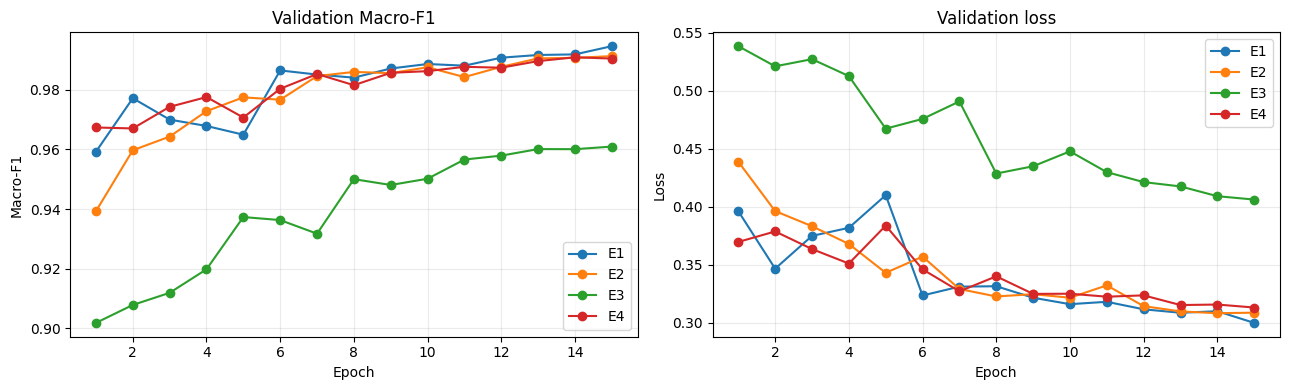

,experiment_id,status,last_completed_epoch,best_epoch,best_val_macro_f1,updated_utc,message
0,E1,completed,15,15.0,0.994599,2026-11-02T19:25:59.217566+00:00,Training completed / early-stopped
1,E2,completed,15,15.0,0.991265,2026-11-02T20:19:53.262584+00:00,Training completed / early-stopped
2,E3,completed,15,15.0,0.960941,2026-11-02T21:04:49.265807+00:00,Training completed / early-stopped
3,E4,completed,15,14.0,0.990867,2026-11-02T21:50:01.966418+00:00,Training completed / early-stopped


In [27]:
if EPOCH_METRICS_PATH.exists():
    epoch_df = pd.read_csv(EPOCH_METRICS_PATH)
    display(epoch_df.sort_values(["experiment_id", "epoch"]).tail(20))
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for exp_id, sub in epoch_df.groupby("experiment_id"):
        axes[0].plot(sub.epoch, sub.val_macro_f1, marker="o", label=exp_id)
        axes[1].plot(sub.epoch, sub.val_loss, marker="o", label=exp_id)
    axes[0].set_title("Validation Macro-F1"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Macro-F1")
    axes[1].set_title("Validation loss"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss")
    for ax in axes: ax.grid(alpha=.25); ax.legend()
    plt.tight_layout(); plt.savefig(DIRS["figures"] / "training_curves.png", dpi=160); plt.show()
else:
    print("No epoch metrics yet. Run E1–E4 first.")

status_df = pd.read_csv(EXPERIMENT_STATUS_PATH) if EXPERIMENT_STATUS_PATH.exists() else pd.DataFrame()
display(status_df)

## 18. Select the final model using validation Macro-F1

The best checkpoint from each completed experiment is evaluated on `val_select`. The winning experiment is selected by validation Macro-F1 only. Test evaluation occurs in the next section after this decision is fixed.

In [28]:
def load_best_model(experiment_id):
    p = DIRS["experiments"] / experiment_id / "best_model.pt"
    if not p.exists():
        raise FileNotFoundError(f"Missing best checkpoint for {experiment_id}: {p}")
    ckpt = read_torch_checkpoint(p, map_location="cpu")
    expected = {
        "experiment_id": experiment_id,
        "model_id": EXPERIMENTS[experiment_id]["model_id"],
        "subset_sha256": SUBSET_SHA,
        "manifest_sha256": MANIFEST_SHA,
        "pretrained_sha256": PRETRAINED_SHA,
        "image_size": IMAGE_SIZE,
        "experiment_recipe": EXPERIMENTS[experiment_id]["recipe"],
    }
    mismatches = [k for k, v in expected.items() if ckpt.get(k) != v]
    if mismatches:
        raise RuntimeError(f"Checkpoint {experiment_id} is incompatible with this workspace/config: {mismatches}")
    model = build_model(experiment_id).to(DEVICE)
    model.load_state_dict(ckpt["model_state_dict"], strict=True)
    model.eval()
    return model, ckpt

val_comparison_rows = []
for exp_id in ["E1", "E2", "E3", "E4"]:
    best_path = DIRS["experiments"] / exp_id / "best_model.pt"
    if not best_path.exists():
        continue
    model, ckpt = load_best_model(exp_id)
    exp = EXPERIMENTS[exp_id]
    val_images = MACENKO_IMAGES["val"][VAL_SELECT_POS] if exp["variant"] == "macenko" else VAL_SELECT_IMAGES
    loader = torch.utils.data.DataLoader(
        PathSubsetDataset(val_images, VAL_SELECT_LABELS, EVAL_TRANSFORM),
        batch_size=BATCH_SIZE*2, shuffle=False, num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type=="cuda")
    )
    criterion = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS, label_smoothing=0.0)
    vloss, vm, vlogits, vy = run_eval_epoch(model, loader, criterion, desc=f"{exp_id} best val")
    val_comparison_rows.append({
        "experiment_id": exp_id, "experiment_name": exp["name"],
        "best_epoch": ckpt["best_epoch"], "best_checkpoint_macro_f1": ckpt["best_val_macro_f1"],
        "val_select_loss": vloss, **{f"val_select_{k}":v for k,v in vm.items()}
    })
    del model, loader, vlogits, vy
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

val_comparison = pd.DataFrame(val_comparison_rows).sort_values("val_select_macro_f1", ascending=False)
if len(val_comparison) != 4:
    raise RuntimeError(f"Expected four completed experiments, found {len(val_comparison)}. Finish the missing experiments before final comparison.")
WINNER_ID = str(val_comparison.iloc[0].experiment_id)
atomic_csv_save(val_comparison, DIRS["logs"] / "validation_experiment_comparison.csv")
display(val_comparison)
print(f"Validation-selected experiment: {WINNER_ID} — {EXPERIMENTS[WINNER_ID]['name']}")

E1 best val:   0%|          | 0/219 [00:00<?, ?it/s]

E2 best val:   0%|          | 0/219 [00:00<?, ?it/s]

E3 best val:   0%|          | 0/219 [00:00<?, ?it/s]

E4 best val:   0%|          | 0/219 [00:00<?, ?it/s]

,experiment_id,experiment_name,best_epoch,best_checkpoint_macro_f1,val_select_loss,val_select_accuracy,val_select_balanced_accuracy,val_select_macro_precision,val_select_macro_recall,val_select_macro_f1,...,val_select_macro_specificity,val_select_top2_accuracy,val_select_mcc,val_select_cohen_kappa,val_select_nll,val_select_brier_score,val_select_ece_15bins,val_select_macro_ovr_auc,val_select_macro_average_precision,val_select_n_samples
0,E1,RGB baseline,15,0.994599,0.068990,0.994573,0.994806,0.994431,0.994806,0.994599,...,0.999324,0.998001,0.993881,0.993876,0.069816,0.011976,0.041245,0.999065,0.997900,3501
1,E2,HED stain augmentation,15,0.991265,0.078460,0.991431,0.991138,0.991419,0.991138,0.991265,...,0.998924,0.998001,0.990332,0.990329,0.077984,0.016704,0.040326,0.999272,0.997637,3501
3,E4,Multi-scale MobileNetV3-Small,14,0.990867,0.085606,0.990860,0.990911,0.990854,0.990911,0.990867,...,0.998854,0.996858,0.989688,0.989685,0.086047,0.019060,0.038248,0.998946,0.995873,3501
2,E3,Macenko stain normalization,15,0.960941,0.183129,0.960297,0.960595,0.961378,0.960595,0.960941,...,0.995004,0.986575,0.955199,0.955189,0.184584,0.067248,0.039037,0.996074,0.983960,3501


Validation-selected experiment: E1 — RGB baseline


## 19. Temperature scaling and selective-prediction threshold selection

The calibration subset (`val_calib`) is separate from the checkpoint-selection subset (`val_select`). Temperature is fitted by minimizing calibration-subset NLL. The abstention threshold is chosen to target the configured coverage on `val_calib`; it is then frozen before the test subset is evaluated.

In [29]:
def get_logits_for_images(model, images, labels, batch_size=BATCH_SIZE):
    loader = torch.utils.data.DataLoader(
        PathSubsetDataset(images, labels, EVAL_TRANSFORM),
        batch_size=batch_size, shuffle=False, num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type=="cuda")
    )
    model.eval(); logits_all=[]; labels_all=[]
    with torch.no_grad():
        for xb, yb, _ in tqdm(loader, desc="Collect logits", leave=False):
            xb = xb.to(DEVICE, non_blocking=True)
            with autocast_context():
                logits = model(xb)
            logits_all.append(logits.float().cpu())
            labels_all.append(yb)
    return torch.cat(logits_all), torch.cat(labels_all).long()

def fit_temperature(logits, labels, max_iter=80):
    logits = logits.detach().double().cpu()
    labels = labels.detach().long().cpu()
    log_t = torch.nn.Parameter(torch.zeros((), dtype=torch.double))
    optimizer = torch.optim.LBFGS([log_t], lr=0.1, max_iter=max_iter, line_search_fn="strong_wolfe")
    def closure():
        optimizer.zero_grad()
        temperature = torch.exp(log_t).clamp(0.05, 20.0)
        loss = F.cross_entropy(logits / temperature, labels)
        loss.backward()
        return loss
    optimizer.step(closure)
    return float(torch.exp(log_t).clamp(0.05,20.0).detach().item())

winner_model, winner_ckpt = load_best_model(WINNER_ID)
winner_variant = EXPERIMENTS[WINNER_ID]["variant"]
if winner_variant == "macenko":
    calib_images = MACENKO_IMAGES["val"][VAL_CALIB_POS]
    test_images_winner = MACENKO_IMAGES["test"]
else:
    calib_images = VAL_CALIB_IMAGES
    test_images_winner = TEST_IMAGES

calib_logits, calib_labels = get_logits_for_images(winner_model, calib_images, VAL_CALIB_LABELS)
TEMPERATURE = fit_temperature(calib_logits, calib_labels)
calib_probs = torch.softmax(calib_logits / TEMPERATURE, dim=1).numpy()
calib_conf = calib_probs.max(axis=1)
# 'lower' quantile selection aims not to undercut the requested calibration coverage.
try:
    ACCEPTANCE_THRESHOLD = float(np.quantile(calib_conf, 1.0-TARGET_COVERAGE, method="lower"))
except TypeError:
    ACCEPTANCE_THRESHOLD = float(np.quantile(calib_conf, 1.0-TARGET_COVERAGE, interpolation="lower"))
calib_accepted = calib_conf >= ACCEPTANCE_THRESHOLD
calib_risk = float(np.mean(calib_probs.argmax(axis=1)[calib_accepted] != calib_labels.numpy()[calib_accepted])) if calib_accepted.any() else np.nan

calibration_decision = {
    "winning_experiment": WINNER_ID,
    "best_epoch": int(winner_ckpt["best_epoch"]),
    "temperature": TEMPERATURE,
    "target_coverage": TARGET_COVERAGE,
    "acceptance_threshold": ACCEPTANCE_THRESHOLD,
    "calibration_coverage": float(calib_accepted.mean()),
    "calibration_selective_risk": calib_risk,
    "calibration_samples": int(len(calib_labels)),
    "subset_sha256": SUBSET_SHA,
    "manifest_sha256": MANIFEST_SHA,
}
atomic_json_save(calibration_decision, DIRS["metadata"] / "calibration_and_abstention_policy.json")
print(json.dumps(calibration_decision, indent=2))

Collect logits:   0%|          | 0/188 [00:00<?, ?it/s]

{
  "winning_experiment": "E1",
  "best_epoch": 15,
  "temperature": 0.7017986260882865,
  "target_coverage": 0.9,
  "acceptance_threshold": 0.9939058423042297,
  "calibration_coverage": 0.9007328447701533,
  "calibration_selective_risk": 0.0029585798816568047,
  "calibration_samples": 1501,
  "subset_sha256": "cec10adc60ad56352746f9c592f477d68851945bb8fe11dd41bc03710ad023df",
  "manifest_sha256": "070006b0d781488b542d7fd9b91ec1f72327864d35b9d559066b5409f2348bbb"
}


## 20. Final test evaluation — run once after experiment choices are fixed

The four predeclared models are evaluated on the same selected test IDs for a final comparison. The validation-selected winner is fixed already; do not change preprocessing, thresholds, epochs, or architecture based on these test results.

In [30]:
all_test_summary = []
all_per_class = []
all_confusions = []
all_prediction_rows = []

for exp_id in ["E1", "E2", "E3", "E4"]:
    model, ckpt = load_best_model(exp_id)
    exp = EXPERIMENTS[exp_id]
    test_images_exp = MACENKO_IMAGES["test"] if exp["variant"] == "macenko" else TEST_IMAGES
    logits, y_true = get_logits_for_images(model, test_images_exp, TEST_LABELS)
    logits_np = logits.numpy()
    probs_raw = torch.softmax(logits, dim=1).numpy()
    metrics = compute_classification_metrics(y_true.numpy(), probs_raw, input_is_probs=True)
    n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    all_test_summary.append({
        "experiment_id": exp_id, "experiment_name": exp["name"],
        "best_epoch": int(ckpt["best_epoch"]),
        "validation_best_macro_f1": float(ckpt["best_val_macro_f1"]),
        "trainable_parameters": int(n_params),
        "fp32_parameter_storage_mb": float(n_params*4/(1024**2)),
        **{f"test_{k}":v for k,v in metrics.items()},
    })
    all_per_class.extend(compute_per_class_metrics(y_true.numpy(), probs_raw, exp_id, "test"))
    cm = confusion_matrix(y_true.numpy(), probs_raw.argmax(axis=1), labels=np.arange(9))
    for i in range(9):
        for j in range(9):
            all_confusions.append({"experiment_id": exp_id, "true_class_id": i, "pred_class_id": j, "count": int(cm[i,j])})
    sample_ids = MANIFEST.loc[MANIFEST.official_split == "test", "sample_id"].tolist()
    for i, sid in enumerate(sample_ids):
        row = {"sample_id": sid, "experiment_id": exp_id, "true_label": int(y_true[i]), "predicted_label": int(probs_raw[i].argmax()), "max_probability": float(probs_raw[i].max())}
        row.update({f"prob_{CLASS_NAMES[c]}": float(probs_raw[i,c]) for c in range(9)})
        all_prediction_rows.append(row)
    del model, logits, y_true
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

test_summary_df = pd.DataFrame(all_test_summary)
per_class_df = pd.DataFrame(all_per_class)
confusion_long_df = pd.DataFrame(all_confusions)
predictions_df = pd.DataFrame(all_prediction_rows)
atomic_csv_save(test_summary_df, DIRS["logs"] / "test_experiment_summary.csv")
atomic_csv_save(per_class_df, DIRS["logs"] / "test_per_class_metrics.csv")
atomic_csv_save(confusion_long_df, DIRS["logs"] / "test_confusion_matrices_long.csv")
atomic_csv_save(predictions_df, DIRS["logs"] / "test_predictions_all_experiments.csv")

display(test_summary_df.sort_values("test_macro_f1", ascending=False))
print("The validation-selected winner remains:", WINNER_ID)

Collect logits:   0%|          | 0/449 [00:00<?, ?it/s]

Collect logits:   0%|          | 0/449 [00:00<?, ?it/s]

Collect logits:   0%|          | 0/449 [00:00<?, ?it/s]

Collect logits:   0%|          | 0/449 [00:00<?, ?it/s]

,experiment_id,experiment_name,best_epoch,validation_best_macro_f1,trainable_parameters,fp32_parameter_storage_mb,test_accuracy,test_balanced_accuracy,test_macro_precision,test_macro_recall,...,test_macro_specificity,test_top2_accuracy,test_mcc,test_cohen_kappa,test_nll,test_brier_score,test_ece_15bins,test_macro_ovr_auc,test_macro_average_precision,test_n_samples
1,E2,HED stain augmentation,15,0.991265,1039721,3.966221,0.964345,0.953557,0.951283,0.953557,...,0.995614,0.987465,0.959071,0.959043,0.195885,0.065983,0.022072,0.994660,0.964352,3590
3,E4,Multi-scale MobileNetV3-Small,14,0.990867,1032457,3.938511,0.949582,0.933827,0.936502,0.933827,...,0.993741,0.978830,0.942282,0.942069,0.255472,0.090377,0.019569,0.992359,0.949333,3590
0,E1,RGB baseline,15,0.994599,1039721,3.966221,0.946518,0.937222,0.929285,0.937222,...,0.993431,0.979666,0.938796,0.938632,0.269989,0.096443,0.012913,0.992312,0.958097,3590
2,E3,Macenko stain normalization,15,0.960941,1039721,3.966221,0.852089,0.834028,0.825856,0.834028,...,0.981908,0.916713,0.832243,0.830905,0.627295,0.246949,0.073891,0.968270,0.847678,3590


The validation-selected winner remains: E1


## 21. Final calibration / selective-prediction evaluation for the validation-selected winner

Temperature scaling does not change the predicted class for a positive scalar temperature; it changes probability calibration. The acceptance threshold is frozen from `val_calib` and evaluated on the test subset.

In [31]:
# Recollect test logits for the validation-selected winner only.
if winner_variant == "macenko":
    test_images_winner = MACENKO_IMAGES["test"]
else:
    test_images_winner = TEST_IMAGES
winner_test_logits, winner_test_labels = get_logits_for_images(winner_model, test_images_winner, TEST_LABELS)
raw_probs = torch.softmax(winner_test_logits, dim=1).numpy()
cal_probs = torch.softmax(winner_test_logits / TEMPERATURE, dim=1).numpy()

raw_cal_metrics = compute_classification_metrics(winner_test_labels.numpy(), raw_probs, input_is_probs=True)
scaled_cal_metrics = compute_classification_metrics(winner_test_labels.numpy(), cal_probs, input_is_probs=True)
conf = cal_probs.max(axis=1)
pred = cal_probs.argmax(axis=1)
accepted = conf >= ACCEPTANCE_THRESHOLD
coverage = float(accepted.mean())
selective_risk = float(np.mean(pred[accepted] != winner_test_labels.numpy()[accepted])) if accepted.any() else np.nan
selective_accuracy = 1.0 - selective_risk if accepted.any() else np.nan

calibration_rows = []
for name, metrics in [("before_temperature_scaling", raw_cal_metrics), ("after_temperature_scaling", scaled_cal_metrics)]:
    calibration_rows.append({"experiment_id": WINNER_ID, "stage": name, "temperature": 1.0 if name.startswith("before") else TEMPERATURE, **metrics})
calibration_df = pd.DataFrame(calibration_rows)
selective_df = pd.DataFrame([{
    "experiment_id": WINNER_ID,
    "target_coverage_on_calibration": TARGET_COVERAGE,
    "calibration_threshold": ACCEPTANCE_THRESHOLD,
    "test_coverage": coverage,
    "test_selective_risk": selective_risk,
    "test_selective_accuracy": selective_accuracy,
    "test_accepted_samples": int(accepted.sum()),
    "test_total_samples": int(len(accepted)),
    "test_abstained_samples": int((~accepted).sum()),
}])
atomic_csv_save(calibration_df, DIRS["logs"] / "winning_model_calibration_metrics.csv")
atomic_csv_save(selective_df, DIRS["logs"] / "winning_model_selective_metrics.csv")

display(calibration_df[["stage", "nll", "brier_score", "ece_15bins", "macro_ovr_auc"]])
display(selective_df)

Collect logits:   0%|          | 0/449 [00:00<?, ?it/s]

,stage,nll,brier_score,ece_15bins,macro_ovr_auc
0,before_temperature_scaling,0.269989,0.096443,0.012913,0.992312
1,after_temperature_scaling,0.320512,0.100676,0.044633,0.992461


,experiment_id,target_coverage_on_calibration,calibration_threshold,test_coverage,test_selective_risk,test_selective_accuracy,test_accepted_samples,test_total_samples,test_abstained_samples
0,E1,0.9,0.993906,0.823955,0.023665,0.976335,2958,3590,632


## 22. Risk–coverage curve for the winning model

The curve is computed on the final test predictions for descriptive evaluation. It is not used to select the threshold; that threshold was fixed on `val_calib`.

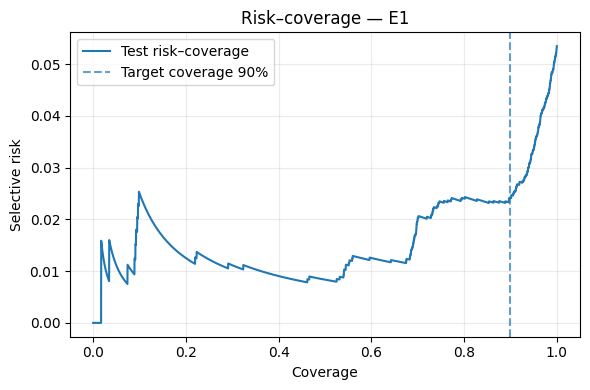

In [32]:
order = np.argsort(-conf)
errors = (pred != winner_test_labels.numpy()).astype(float)[order]
coverages = np.arange(1, len(errors)+1) / len(errors)
risks = np.cumsum(errors) / np.arange(1, len(errors)+1)
fig, ax = plt.subplots(figsize=(6,4))
ax.plot(coverages, risks, label="Test risk–coverage")
ax.axvline(TARGET_COVERAGE, linestyle="--", alpha=.7, label=f"Target coverage {TARGET_COVERAGE:.0%}")
ax.set_xlabel("Coverage"); ax.set_ylabel("Selective risk"); ax.set_title(f"Risk–coverage — {WINNER_ID}")
ax.grid(alpha=.25); ax.legend(); plt.tight_layout()
fig.savefig(DIRS["figures"] / "winning_model_risk_coverage.png", dpi=160)
plt.show()

## 23. Grad-CAM — class-specific visualization on validation samples

Grad-CAM is generated from the final convolutional feature layer of the selected model. It highlights regions associated with a chosen class score; it is not a pixel-level tissue segmentation or proof of biological reasoning. Examples are selected from `val_select`, not from the test subset.

In [33]:
def gradcam_heatmap(model, image_tensor, target_class=None):
    model.eval()
    activation = {}
    def forward_hook(module, inputs, output):
        activation["features"] = output
        output.register_hook(lambda grad: activation.__setitem__("gradients", grad))
    handle = model.cam_layer.register_forward_hook(forward_hook)
    try:
        model.zero_grad(set_to_none=True)
        logits = model(image_tensor.to(DEVICE))
        if target_class is None:
            target_class = int(logits.argmax(dim=1).item())
        score = logits[:, target_class].sum()
        score.backward()
        features = activation["features"].detach()
        gradients = activation["gradients"].detach()
        weights = gradients.mean(dim=(2,3), keepdim=True)
        cam = torch.relu((weights * features).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=(IMAGE_SIZE, IMAGE_SIZE), mode="bilinear", align_corners=False)
        cam = cam[0,0].cpu().numpy()
        cam = (cam-cam.min()) / (cam.max()-cam.min()+1e-8)
        return cam, target_class, logits.detach().cpu().numpy()[0]
    finally:
        handle.remove()
        model.zero_grad(set_to_none=True)

# Build deterministic val loader for raw or Macenko images.
val_cam_images = MACENKO_IMAGES["val"][VAL_SELECT_POS] if winner_variant == "macenko" else VAL_SELECT_IMAGES
cam_candidates = []
for cls in range(9):
    ids = np.flatnonzero(VAL_SELECT_LABELS == cls)
    if len(ids):
        cam_candidates.extend(ids[:min(2, len(ids))].tolist())

cam_dir = DIRS["figures"] / "gradcam_examples"
cam_dir.mkdir(parents=True, exist_ok=True)
cam_rows = []
for idx in tqdm(cam_candidates, desc="Generate Grad-CAM examples"):
    original = val_cam_images[idx]
    tensor = EVAL_TRANSFORM(Image.fromarray(original)).unsqueeze(0)
    cam, predicted_class, logits_1d = gradcam_heatmap(winner_model, tensor)
    probs = torch.softmax(torch.tensor(logits_1d), dim=0).numpy()
    overlay = np.clip(0.55*(original.astype(np.float32)/255.0) + 0.45*plt.get_cmap("jet")(cam)[...,:3], 0, 1)
    fig, axes = plt.subplots(1,3, figsize=(10,3.4))
    axes[0].imshow(original); axes[0].set_title(f"Original | true={CLASS_NAMES[int(VAL_SELECT_LABELS[idx])]}")
    axes[1].imshow(cam, cmap="jet"); axes[1].set_title("Grad-CAM")
    axes[2].imshow(overlay); axes[2].set_title(f"Overlay | pred={CLASS_NAMES[predicted_class]} ({probs.max():.2f})")
    for ax in axes: ax.axis("off")
    plt.tight_layout()
    out_path = cam_dir / f"val_{idx:04d}_true_{int(VAL_SELECT_LABELS[idx])}_pred_{predicted_class}.png"
    fig.savefig(out_path, dpi=140, bbox_inches="tight"); plt.close(fig)
    cam_rows.append({"val_select_position": int(idx), "true_label": int(VAL_SELECT_LABELS[idx]), "predicted_label": int(predicted_class), "max_probability": float(probs.max()), "image_file": out_path.name})
atomic_csv_save(pd.DataFrame(cam_rows), DIRS["logs"] / "gradcam_examples_manifest.csv")
print("Grad-CAM figures saved to:", cam_dir)

Generate Grad-CAM examples:   0%|          | 0/18 [00:00<?, ?it/s]

Grad-CAM figures saved to: C:\Users\saibh\Videos\CV_MODEL\PathoLens_Workspace_50pct\figures\gradcam_examples


## 24. Learned-representation analysis (PCA on validation features)

This is exploratory EDA on the selected model's feature embeddings from `val_select`. PCA is fitted only to these validation embeddings for visualization. The plot is not a performance metric and does not establish biological separability.

Extract validation embeddings:   0%|          | 0/219 [00:00<?, ?it/s]

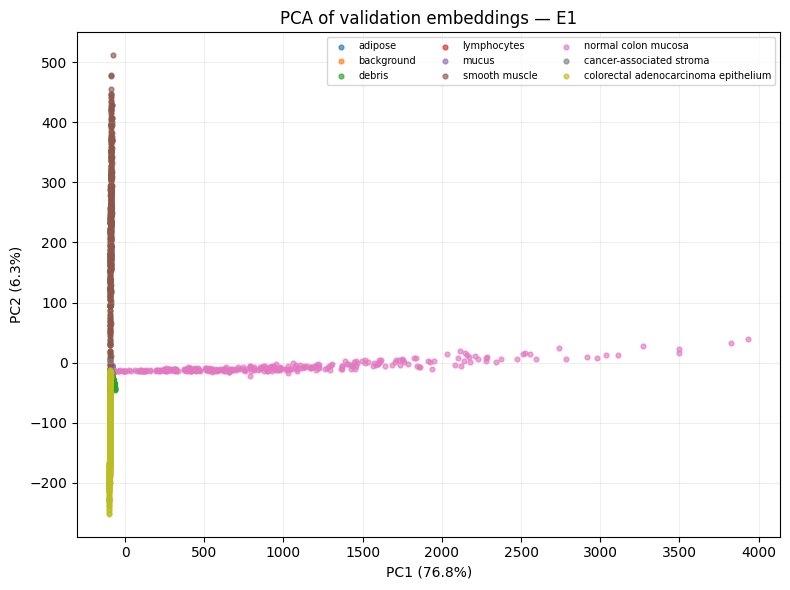

In [34]:
@torch.no_grad()
def extract_embeddings(model, images, labels, batch_size=BATCH_SIZE*2):
    loader = torch.utils.data.DataLoader(
        PathSubsetDataset(images, labels, EVAL_TRANSFORM), batch_size=batch_size,
        shuffle=False, num_workers=NUM_WORKERS, pin_memory=(DEVICE.type=="cuda")
    )
    model.eval(); emb=[]; ys=[]
    for xb, yb, _ in tqdm(loader, desc="Extract validation embeddings", leave=False):
        xb = xb.to(DEVICE, non_blocking=True)
        with autocast_context():
            z = model.extract_embedding(xb)
        emb.append(z.float().cpu().numpy()); ys.append(yb.numpy())
    return np.concatenate(emb), np.concatenate(ys)

embeddings, emb_labels = extract_embeddings(winner_model, val_cam_images, VAL_SELECT_LABELS)
pca = PCA(n_components=2, random_state=SEED)
emb_2d = pca.fit_transform(embeddings)
fig, ax = plt.subplots(figsize=(8,6))
for cls in range(9):
    m = emb_labels == cls
    ax.scatter(emb_2d[m,0], emb_2d[m,1], s=12, alpha=.65, label=CLASS_NAMES[cls])
ax.set_title(f"PCA of validation embeddings — {WINNER_ID}")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
ax.legend(fontsize=7, ncol=3); ax.grid(alpha=.2); plt.tight_layout()
fig.savefig(DIRS["figures"] / "winning_model_validation_pca.png", dpi=160); plt.show()

## 25. Efficiency profiling

The parameter count and weight storage are exact for the implemented model. FLOPs are estimated with `thop` if available; if it is unavailable, the notebook records NaN rather than inventing a value. Inference latency is measured on the current runtime after warm-up.

In [35]:
def profile_model_efficiency(experiment_id):
    model, ckpt = load_best_model(experiment_id)
    model.eval()
    params = sum(p.numel() for p in model.parameters())
    fp32_mb = sum(p.numel()*p.element_size() for p in model.parameters())/(1024**2)
    flops = np.nan
    try:
        from thop import profile
        dummy = torch.zeros(1,3,IMAGE_SIZE,IMAGE_SIZE,device=DEVICE)
        macs, _ = profile(model, inputs=(dummy,), verbose=False)
        flops = float(2*macs)
    except Exception:
        pass
    dummy = torch.randn(1,3,IMAGE_SIZE,IMAGE_SIZE,device=DEVICE)
    with torch.no_grad():
        for _ in range(10):
            _ = model(dummy)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        t0 = time.perf_counter()
        repeats = 50
        for _ in range(repeats):
            _ = model(dummy)
        if DEVICE.type == "cuda": torch.cuda.synchronize()
        latency_ms = (time.perf_counter()-t0)*1000/repeats
    best_ckpt_path = DIRS["experiments"] / experiment_id / "best_model.pt"
    result = {
        "experiment_id": experiment_id,
        "model_id": EXPERIMENTS[experiment_id]["model_id"],
        "trainable_parameters": int(params),
        "fp32_parameter_storage_mb": float(fp32_mb),
        "best_checkpoint_file_mb": float(best_ckpt_path.stat().st_size/(1024**2)) if best_ckpt_path.exists() else np.nan,
        "estimated_flops_per_image": float(flops) if np.isfinite(flops) else np.nan,
        "batch1_inference_latency_ms": float(latency_ms),
        "device": str(DEVICE),
    }
    del model, dummy; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    return result

efficiency_rows = [profile_model_efficiency(e) for e in ["E1","E2","E3","E4"]]
efficiency_df = pd.DataFrame(efficiency_rows)
atomic_csv_save(efficiency_df, DIRS["logs"] / "efficiency_metrics.csv")
display(efficiency_df)

,experiment_id,model_id,trainable_parameters,fp32_parameter_storage_mb,best_checkpoint_file_mb,estimated_flops_per_image,batch1_inference_latency_ms,device
0,E1,mobilenet_v3_small_compact_head_v1,1039721,3.966221,4.087914,40595952.0,5.204400,cuda:0
1,E2,mobilenet_v3_small_compact_head_v1,1039721,3.966221,4.087914,40595952.0,5.805058,cuda:0
2,E3,mobilenet_v3_small_compact_head_v1,1039721,3.966221,4.087914,40595952.0,5.131924,cuda:0
3,E4,mobilenet_v3_small_multiscale_head_v1,1032457,3.938511,4.060712,40564272.0,7.234898,cuda:0


## 26. Experiment summary and final results table

The final summary combines validation checkpoint selection, test classification metrics, parameter counts, calibration, and selective-prediction results. The validation-selected winner is identified separately from the experiment with the highest test score.

In [36]:
final_summary = test_summary_df.merge(
    val_comparison[["experiment_id","val_select_macro_f1","best_checkpoint_macro_f1"]],
    on="experiment_id", how="left"
).merge(efficiency_df[["experiment_id","estimated_flops_per_image","batch1_inference_latency_ms"]], on="experiment_id", how="left")
final_summary["validation_selected_winner"] = final_summary.experiment_id.eq(WINNER_ID)
atomic_csv_save(final_summary, DIRS["logs"] / "final_experiment_summary.csv")
display(final_summary.sort_values("val_select_macro_f1", ascending=False))
print("Selected on validation only:", WINNER_ID)
print("Do not choose a different model merely because its test score is higher.")

,experiment_id,experiment_name,best_epoch,validation_best_macro_f1,trainable_parameters,fp32_parameter_storage_mb,test_accuracy,test_balanced_accuracy,test_macro_precision,test_macro_recall,...,test_brier_score,test_ece_15bins,test_macro_ovr_auc,test_macro_average_precision,test_n_samples,val_select_macro_f1,best_checkpoint_macro_f1,estimated_flops_per_image,batch1_inference_latency_ms,validation_selected_winner
0,E1,RGB baseline,15,0.994599,1039721,3.966221,0.946518,0.937222,0.929285,0.937222,...,0.096443,0.012913,0.992312,0.958097,3590,0.994599,0.994599,40595952.0,5.204400,True
1,E2,HED stain augmentation,15,0.991265,1039721,3.966221,0.964345,0.953557,0.951283,0.953557,...,0.065983,0.022072,0.994660,0.964352,3590,0.991265,0.991265,40595952.0,5.805058,False
3,E4,Multi-scale MobileNetV3-Small,14,0.990867,1032457,3.938511,0.949582,0.933827,0.936502,0.933827,...,0.090377,0.019569,0.992359,0.949333,3590,0.990867,0.990867,40564272.0,7.234898,False
2,E3,Macenko stain normalization,15,0.960941,1039721,3.966221,0.852089,0.834028,0.825856,0.834028,...,0.246949,0.073891,0.968270,0.847678,3590,0.960941,0.960941,40595952.0,5.131924,False


Selected on validation only: E1
Do not choose a different model merely because its test score is higher.


## 27. Save run metadata and environment information

This captures the software versions, hardware, dataset identity, subset hashes, experiment configurations, and calibration policy needed to interpret or continue the run on another machine.

In [37]:
import importlib.metadata as importlib_metadata

def version_or_missing(package):
    try: return importlib_metadata.version(package)
    except Exception: return "not-installed"

run_metadata = {
    "project": PROJECT_NAME,
    "notebook_version": NOTEBOOK_VERSION,
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "dataset": SUBSET_CONFIG,
    "subset_sha256": SUBSET_SHA,
    "manifest_sha256": MANIFEST_SHA,
    "pretrained_sha256": PRETRAINED_SHA,
    "class_names": CLASS_NAMES,
    "validation_roles": {"val_select": int(len(VAL_SELECT_POS)), "val_calib": int(len(VAL_CALIB_POS))},
    "experiments": EXPERIMENTS,
    "winner_selected_by_validation_macro_f1": WINNER_ID,
    "calibration_policy": calibration_decision,
    "training_config": {
        "epochs": EPOCHS, "batch_size": BATCH_SIZE, "backbone_lr": BACKBONE_LR,
        "head_lr": HEAD_LR, "weight_decay": WEIGHT_DECAY,
        "label_smoothing": LABEL_SMOOTHING, "warmup_epochs": WARMUP_EPOCHS,
        "early_stopping_patience": EARLY_STOPPING_PATIENCE,
        "gradient_clip_norm": GRAD_CLIP_NORM, "amp_requested": USE_AMP,
        "amp_enabled": AMP_ENABLED, "num_workers": NUM_WORKERS,
    },
    "environment": {
        "python": sys.version,
        "platform": platform.platform(),
        "torch": torch.__version__,
        "torchvision": torchvision.__version__,
        "medmnist": MEDMNIST_VERSION,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "scikit_image": version_or_missing("scikit-image"),
        "scikit_learn": version_or_missing("scikit-learn"),
        "cuda_available": torch.cuda.is_available(),
        "cuda_version": torch.version.cuda,
        "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
    },
}
atomic_json_save(run_metadata, DIRS["metadata"] / "run_metadata.json")

requirements_text = """medmnist\nscikit-image\nscikit-learn\npandas\nmatplotlib\ntqdm\n# Install torch and torchvision from the official PyTorch selector for your OS/CUDA setup.\n"""
(DIRS["metadata"] / "requirements.txt").write_text(requirements_text)
env_text = "\n".join([f"python={sys.version}", f"platform={platform.platform()}", f"torch={torch.__version__}", f"torchvision={torchvision.__version__}", f"medmnist={MEDMNIST_VERSION}", f"cuda={torch.version.cuda}", f"device={DEVICE}"])
(DIRS["metadata"] / "environment.txt").write_text(env_text)
print("Run metadata saved.")

Run metadata saved.


## 28. Save local run instructions and artifact inventory

The workspace is already stored on the laptop. This cell writes a README and an inventory CSV so you can identify the dataset, logs and checkpoints later. To move the run to another machine, copy the entire `PathoLens_Workspace` directory manually or use your preferred local backup method.

In [38]:
README_TEXT = f"""# PathoLens AI — Local GPU Experiment Workspace

## Local-only storage
All data, derived data, checkpoints, logs, figures and metadata are stored in:
`{WORKSPACE_ROOT}`

No Google Drive or Colab mount is used by this notebook.

## Dataset
- Dataset: PathMNIST size {DATA_SIZE}
- Subset fraction within each official split: {SUBSET_FRACTION}
- Sampling seed: {SEED}
- Subset SHA256: {SUBSET_SHA}
- Manifest SHA256: {MANIFEST_SHA}

## Experiments
- E1: MobileNetV3-Small original RGB baseline
- E2: MobileNetV3-Small with H&E stain perturbation
- E3: MobileNetV3-Small with Macenko normalization fitted from training images only
- E4: lightweight multi-scale MobileNetV3-Small

## Recovery
- `experiments/E*/best_model.pt`: best validation Macro-F1 model
- `experiments/E*/last_checkpoint.pt`: latest completed-epoch full-state checkpoint
- `logs/epoch_metrics.csv`: one row per completed epoch
- `logs/experiment_status.csv`: current experiment status

Rerun this notebook from the top after an interruption. It reuses the matching local subset, skips completed experiments, and resumes unfinished experiments after verifying dataset and configuration hashes.

## Important
- Test data is not used for checkpoint selection, calibration fitting or threshold selection.
- The test subset is 50% of the official test split; report results as a half-dataset pilot.
- Patient/slide-level independence cannot be confirmed from the manifest alone.
- Cross-GPU bitwise reproducibility is not guaranteed.
"""
(DIRS["metadata"] / "README_local_workspace.md").write_text(README_TEXT, encoding="utf-8")

inventory_rows = []
for folder_name in ["shared_dataset", "pretrained", "derived_data", "experiments", "logs", "figures", "metadata"]:
    base = WORKSPACE_ROOT / folder_name
    if base.exists():
        for path in base.rglob("*"):
            if path.is_file() and not path.name.endswith(".tmp"):
                inventory_rows.append({
                    "relative_path": str(path.relative_to(WORKSPACE_ROOT)),
                    "size_mb": round(path.stat().st_size / (1024**2), 4),
                    "sha256": sha256_file(path) if path.suffix in {".npz", ".pt", ".json", ".csv"} else "not_calculated",
                })
inventory_df = pd.DataFrame(inventory_rows)
atomic_csv_save(inventory_df, DIRS["metadata"] / "artifact_inventory.csv")
print("Local README:", DIRS["metadata"] / "README_local_workspace.md")
print("Artifact inventory:", DIRS["metadata"] / "artifact_inventory.csv")
print("Workspace size (GB):", round(sum(p.stat().st_size for p in WORKSPACE_ROOT.rglob("*") if p.is_file()) / (1024**3), 3))
display(inventory_df.head(25))

Local README: C:\Users\saibh\Videos\CV_MODEL\PathoLens_Workspace_50pct\metadata\README_local_workspace.md
Artifact inventory: C:\Users\saibh\Videos\CV_MODEL\PathoLens_Workspace_50pct\metadata\artifact_inventory.csv
Workspace size (GB): 8.961


,relative_path,size_mb,sha256
0,shared_dataset\dataset_metadata.json,0.0007,e5a50535b4ab31f4b3191687087627aadbb575cc248fe7...
1,shared_dataset\subset_identity.json,0.0011,cec10adc60ad56352746f9c592f477d68851945bb8fe11...
2,shared_dataset\subset_manifest.csv,2.7674,070006b0d781488b542d7fd9b91ec1f72327864d35b9d5...
3,shared_dataset\arrays\test_images.npy,168.2814,not_calculated
4,shared_dataset\arrays\test_indices.npy,0.0275,not_calculated
5,shared_dataset\arrays\test_labels.npy,0.0275,not_calculated
6,shared_dataset\arrays\train_images.npy,2109.2814,not_calculated
7,shared_dataset\arrays\train_indices.npy,0.3434,not_calculated
8,shared_dataset\arrays\train_labels.npy,0.3434,not_calculated
9,shared_dataset\arrays\val_images.npy,234.4689,not_calculated


## 29. Final local audit checklist

Before reporting or sharing results, verify:

- [ ] The notebook preflight identified the intended NVIDIA GPU and `DEVICE` is `cuda:0`.
- [ ] All four experiment statuses are `completed` (or clearly labelled interrupted/pending).
- [ ] Each completed experiment has `best_model.pt` and `last_checkpoint.pt`.
- [ ] `epoch_metrics.csv` has each completed epoch and no duplicate experiment/epoch rows.
- [ ] Dataset and manifest hashes match the hashes recorded in the checkpoints.
- [ ] The winning experiment was selected using validation Macro-F1, not test accuracy.
- [ ] Temperature and abstention threshold were fitted on `val_calib`, not test.
- [ ] Test metrics are labelled as 10%-subset pilot results.
- [ ] `README_local_workspace.md` and `artifact_inventory.csv` are present.
- [ ] The full `PathoLens_Workspace` folder is included in your local backup if you need to preserve or transfer the run.

## Technical references

- MedMNIST dataset API and size variants: https://github.com/MedMNIST/MedMNIST
- Torchvision MobileNetV3-Small: https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.mobilenet_v3_small.html
- Official PyTorch local CUDA installation selector: https://pytorch.org/get-started/locally/

**Research disclaimer:** PathoLens is an educational/research prototype for patch-level tissue classification. It is not a patient-level diagnostic system or a clinically validated decision-support tool.


## 30. Post-run checkpoint audit — verify all four trained models

This section creates a manifest for the four model checkpoints actually used. A checkpoint must pass metadata checks and strict state-dict loading before it is accepted. The manifest records file size and SHA-256 so the weights can be identified later.


In [39]:

checkpoint_audit_rows = []
for exp_id in ["E1", "E2", "E3", "E4"]:
    ckpt_path = DIRS["experiments"] / exp_id / "best_model.pt"
    if not ckpt_path.exists():
        raise FileNotFoundError(f"Missing model checkpoint after training/recovery: {ckpt_path}")
    model, ckpt = load_best_model(exp_id)
    checkpoint_audit_rows.append({
        "experiment_id": exp_id,
        "experiment_name": EXPERIMENTS[exp_id]["name"],
        "model_id": ckpt["model_id"],
        "best_epoch": int(ckpt["best_epoch"]),
        "best_val_macro_f1_in_checkpoint": float(ckpt["best_val_macro_f1"]),
        "checkpoint_path": str(ckpt_path),
        "checkpoint_size_mb": ckpt_path.stat().st_size / (1024**2),
        "checkpoint_sha256": sha256_file(ckpt_path),
        "strict_state_dict_load": True,
        "dataset_hash_match": ckpt.get("subset_sha256") == SUBSET_SHA,
        "manifest_hash_match": ckpt.get("manifest_sha256") == MANIFEST_SHA,
    })
    del model
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()

checkpoint_audit_df = pd.DataFrame(checkpoint_audit_rows)
atomic_csv_save(checkpoint_audit_df, DIRS["logs"] / "checkpoint_audit_all_experiments.csv")
display(checkpoint_audit_df)
assert len(checkpoint_audit_df) == 4 and checkpoint_audit_df["strict_state_dict_load"].all()


,experiment_id,experiment_name,model_id,best_epoch,best_val_macro_f1_in_checkpoint,checkpoint_path,checkpoint_size_mb,checkpoint_sha256,strict_state_dict_load,dataset_hash_match,manifest_hash_match
0,E1,RGB baseline,mobilenet_v3_small_compact_head_v1,15,0.994599,C:\Users\saibh\Videos\CV_MODEL\PathoLens_Works...,4.087914,3ca6a6417ab2bc085837cf1bcb0b41497bc89036e53f57...,True,True,True
1,E2,HED stain augmentation,mobilenet_v3_small_compact_head_v1,15,0.991265,C:\Users\saibh\Videos\CV_MODEL\PathoLens_Works...,4.087914,018103b7dafa00508f95999f963fe23ccf11e5085a43c4...,True,True,True
2,E3,Macenko stain normalization,mobilenet_v3_small_compact_head_v1,15,0.960941,C:\Users\saibh\Videos\CV_MODEL\PathoLens_Works...,4.087914,10429725238c574be27140e99d8e51547bb1f0101d37a1...,True,True,True
3,E4,Multi-scale MobileNetV3-Small,mobilenet_v3_small_multiscale_head_v1,14,0.990867,C:\Users\saibh\Videos\CV_MODEL\PathoLens_Works...,4.060712,2eac259fa040ecbfcae35c8ced277591dc11abedfe512e...,True,True,True



## 31. Detailed validation error analysis

This analysis uses `val_select` to characterize the selected model before the final test results are interpreted. It identifies correct, incorrect, confident-error, and low-confidence validation examples for later visual inspection.


In [40]:

# Reuse the winner model already loaded above and evaluate on the checkpoint-selection split.
val_logits_winner, val_labels_winner = get_logits_for_images(winner_model, val_cam_images, VAL_SELECT_LABELS)
val_probs_winner = torch.softmax(val_logits_winner, dim=1).numpy()
val_pred_winner = val_probs_winner.argmax(axis=1)
val_conf_winner = val_probs_winner.max(axis=1)
val_entropy_winner = -(np.clip(val_probs_winner, 1e-12, 1.0) * np.log(np.clip(val_probs_winner, 1e-12, 1.0))).sum(axis=1)
val_error_rows = []
for i in range(len(VAL_SELECT_LABELS)):
    val_error_rows.append({
        "val_select_position": int(i),
        "true_label": int(VAL_SELECT_LABELS[i]),
        "true_class": CLASS_NAMES[int(VAL_SELECT_LABELS[i])],
        "predicted_label": int(val_pred_winner[i]),
        "predicted_class": CLASS_NAMES[int(val_pred_winner[i])],
        "correct": bool(val_pred_winner[i] == VAL_SELECT_LABELS[i]),
        "max_probability": float(val_conf_winner[i]),
        "predictive_entropy": float(val_entropy_winner[i]),
        "normalized_entropy": float(val_entropy_winner[i] / np.log(9)),
    })
val_error_df = pd.DataFrame(val_error_rows)
atomic_csv_save(val_error_df, DIRS["logs"] / "winning_model_validation_predictions_and_uncertainty.csv")
display(val_error_df.sort_values(["correct", "max_probability"], ascending=[True, False]).head(20))
print("Validation misclassifications:", int((~val_error_df.correct).sum()), "/", len(val_error_df))


Collect logits:   0%|          | 0/438 [00:00<?, ?it/s]

,val_select_position,true_label,true_class,predicted_label,predicted_class,correct,max_probability,predictive_entropy,normalized_entropy
3160,3160,7,cancer-associated stroma,4,mucus,False,0.961242,0.244410,0.111236
1309,1309,2,debris,7,cancer-associated stroma,False,0.957290,0.265097,0.120651
1909,1909,4,mucus,7,cancer-associated stroma,False,0.957188,0.265536,0.120851
1696,1696,5,smooth muscle,7,cancer-associated stroma,False,0.955975,0.271236,0.123445
1617,1617,2,debris,7,cancer-associated stroma,False,0.955779,0.272379,0.123965
2895,2895,5,smooth muscle,7,cancer-associated stroma,False,0.955679,0.272781,0.124148
3429,3429,2,debris,7,cancer-associated stroma,False,0.955337,0.274973,0.125146
2983,2983,7,cancer-associated stroma,2,debris,False,0.954916,0.277333,0.126220
610,610,2,debris,7,cancer-associated stroma,False,0.951807,0.292924,0.133316
2330,2330,2,debris,5,smooth muscle,False,0.950435,0.299993,0.136532


Validation misclassifications: 19 / 3501



## 32. Grad-CAM coverage: correct, incorrect, confident-error and uncertain cases

The earlier Grad-CAM section creates class-representative examples. This additional section deliberately samples several prediction behaviours from `val_select`: one high-confidence correct example per class, one high-confidence misclassification per true class when available, and a few globally low-confidence cases. It does not use the test set to choose explanations.


In [41]:

import copy

detailed_cam_cases = []
for cls in range(9):
    cls_ids = np.flatnonzero(VAL_SELECT_LABELS == cls)
    if len(cls_ids) == 0:
        continue
    correct_ids = [i for i in cls_ids if val_pred_winner[i] == cls]
    wrong_ids = [i for i in cls_ids if val_pred_winner[i] != cls]
    if correct_ids:
        best_correct = max(correct_ids, key=lambda i: val_conf_winner[i])
        detailed_cam_cases.append((best_correct, "high_confidence_correct"))
    if wrong_ids:
        confident_error = max(wrong_ids, key=lambda i: val_conf_winner[i])
        detailed_cam_cases.append((confident_error, "high_confidence_error"))
# Add up to five globally least-confident examples (unique positions only).
for idx in np.argsort(val_conf_winner)[:5]:
    if not any(existing_idx == int(idx) for existing_idx, _ in detailed_cam_cases):
        detailed_cam_cases.append((int(idx), "low_confidence"))

# Keep a deterministic, unique set and preserve its explanation category.
seen_cam_positions = set()
unique_cam_cases = []
for idx, category in detailed_cam_cases:
    if idx not in seen_cam_positions:
        unique_cam_cases.append((idx, category))
        seen_cam_positions.add(idx)

detailed_cam_dir = DIRS["figures"] / "gradcam_detailed"
detailed_cam_dir.mkdir(parents=True, exist_ok=True)
detailed_cam_rows = []
for idx, category in tqdm(unique_cam_cases, desc="Detailed validation Grad-CAM"):
    original = val_cam_images[idx]
    tensor = EVAL_TRANSFORM(Image.fromarray(original)).unsqueeze(0)
    cam, predicted_class, logits_1d = gradcam_heatmap(winner_model, tensor)
    probs = torch.softmax(torch.tensor(logits_1d), dim=0).numpy()
    true_class = int(VAL_SELECT_LABELS[idx])
    overlay = np.clip(0.55 * (original.astype(np.float32) / 255.0) + 0.45 * plt.get_cmap("jet")(cam)[..., :3], 0, 1)
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
    axes[0].imshow(original); axes[0].set_title(f"Original | true={CLASS_NAMES[true_class]}")
    axes[1].imshow(cam, cmap="jet"); axes[1].set_title("Grad-CAM")
    axes[2].imshow(overlay); axes[2].set_title(f"pred={CLASS_NAMES[predicted_class]} | p={probs.max():.2f}")
    for ax in axes: ax.axis("off")
    fig.suptitle(f"{WINNER_ID} | {category}", fontsize=10)
    plt.tight_layout()
    out_path = detailed_cam_dir / f"{category}_valpos_{idx:04d}_true_{true_class}_pred_{predicted_class}.png"
    fig.savefig(out_path, dpi=150, bbox_inches="tight")
    plt.close(fig)
    detailed_cam_rows.append({
        "experiment_id": WINNER_ID, "val_select_position": int(idx), "case_type": category,
        "true_class": CLASS_NAMES[true_class], "predicted_class": CLASS_NAMES[int(predicted_class)],
        "correct": bool(true_class == int(predicted_class)), "max_probability": float(probs.max()),
        "normalized_entropy": float(val_entropy_winner[idx] / np.log(9)), "image_file": out_path.name,
    })
detailed_cam_df = pd.DataFrame(detailed_cam_rows)
atomic_csv_save(detailed_cam_df, DIRS["logs"] / "gradcam_detailed_manifest.csv")
display(detailed_cam_df)
print("Detailed Grad-CAM images:", detailed_cam_dir)


Detailed validation Grad-CAM:   0%|          | 0/20 [00:00<?, ?it/s]

,experiment_id,val_select_position,case_type,true_class,predicted_class,correct,max_probability,normalized_entropy,image_file
0,E1,2754,high_confidence_correct,adipose,adipose,True,0.957880,0.119141,high_confidence_correct_valpos_2754_true_0_pre...
1,E1,2964,high_confidence_correct,background,background,True,0.957627,0.119678,high_confidence_correct_valpos_2964_true_1_pre...
2,E1,3161,high_confidence_correct,debris,debris,True,0.956038,0.123426,high_confidence_correct_valpos_3161_true_2_pre...
3,E1,1309,high_confidence_error,debris,cancer-associated stroma,False,0.957290,0.120651,high_confidence_error_valpos_1309_true_2_pred_...
4,E1,1232,high_confidence_correct,lymphocytes,lymphocytes,True,0.955866,0.123854,high_confidence_correct_valpos_1232_true_3_pre...
5,E1,302,high_confidence_correct,mucus,mucus,True,0.961510,0.110555,high_confidence_correct_valpos_0302_true_4_pre...
6,E1,1909,high_confidence_error,mucus,cancer-associated stroma,False,0.957109,0.120851,high_confidence_error_valpos_1909_true_4_pred_...
7,E1,2748,high_confidence_correct,smooth muscle,smooth muscle,True,0.951233,0.134535,high_confidence_correct_valpos_2748_true_5_pre...
8,E1,1696,high_confidence_error,smooth muscle,cancer-associated stroma,False,0.955951,0.123445,high_confidence_error_valpos_1696_true_5_pred_...
9,E1,1644,high_confidence_correct,normal colon mucosa,normal colon mucosa,True,0.962874,0.107191,high_confidence_correct_valpos_1644_true_6_pre...


Detailed Grad-CAM images: C:\Users\saibh\Videos\CV_MODEL\PathoLens_Workspace_50pct\figures\gradcam_detailed



## 33. Grad-CAM parameter-randomization sanity check

A useful sanity check is to compare a trained model's Grad-CAM with the map obtained after randomizing the classifier head while keeping the input image fixed. A large difference is evidence that the explanation depends on learned classifier parameters. This is a limited head-randomization check, not a complete explanation-faithfulness proof.


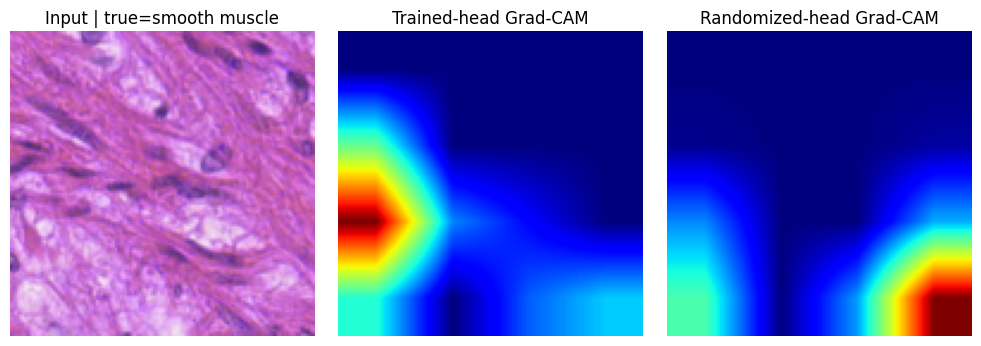

,experiment_id,val_select_position,target_class,trained_vs_randomized_cam_pearson,trained_vs_randomized_cam_mae,interpretation
0,E1,0,smooth muscle,0.372069,0.158158,Compare maps visually and numerically; this si...


In [42]:

# Choose a deterministic validation example; prefer a correctly classified sample.
correct_val_ids = np.flatnonzero(val_pred_winner == VAL_SELECT_LABELS)
san_idx = int(correct_val_ids[0] if len(correct_val_ids) else 0)
san_image = val_cam_images[san_idx]
san_tensor = EVAL_TRANSFORM(Image.fromarray(san_image)).unsqueeze(0)
trained_cam, trained_target, trained_logits = gradcam_heatmap(winner_model, san_tensor)

random_head_model = copy.deepcopy(winner_model).to(DEVICE)
for module in random_head_model.head_module.modules():
    if hasattr(module, "reset_parameters"):
        module.reset_parameters()
random_cam, random_target, random_logits = gradcam_heatmap(random_head_model, san_tensor, target_class=trained_target)
cam_corr = float(np.corrcoef(trained_cam.reshape(-1), random_cam.reshape(-1))[0, 1]) if np.std(trained_cam) > 0 and np.std(random_cam) > 0 else np.nan
cam_mae = float(np.mean(np.abs(trained_cam - random_cam)))
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4))
axes[0].imshow(san_image); axes[0].set_title(f"Input | true={CLASS_NAMES[int(VAL_SELECT_LABELS[san_idx])]}" )
axes[1].imshow(trained_cam, cmap="jet"); axes[1].set_title("Trained-head Grad-CAM")
axes[2].imshow(random_cam, cmap="jet"); axes[2].set_title("Randomized-head Grad-CAM")
for ax in axes: ax.axis("off")
plt.tight_layout(); fig.savefig(DIRS["figures"] / "gradcam_head_randomization_sanity.png", dpi=160); plt.show()
randomization_result = pd.DataFrame([{
    "experiment_id": WINNER_ID, "val_select_position": san_idx,
    "target_class": CLASS_NAMES[int(trained_target)], "trained_vs_randomized_cam_pearson": cam_corr,
    "trained_vs_randomized_cam_mae": cam_mae,
    "interpretation": "Compare maps visually and numerically; this single-example head-randomization check is not proof of faithfulness."
}])
atomic_csv_save(randomization_result, DIRS["logs"] / "gradcam_randomization_sanity.csv")
display(randomization_result)
del random_head_model
if torch.cuda.is_available(): torch.cuda.empty_cache()



## 34. Grad-CAM stability under 90-degree rotations

The training recipe includes right-angle rotations. For a small validation sample, this section rotates an image by 90 degrees, computes a second map, rotates that map back, and compares it with the original map. This is an exploratory stability check, not a ground-truth explanation metric.


In [43]:

stability_rows = []
stability_positions = []
for cls in range(9):
    ids = np.flatnonzero(VAL_SELECT_LABELS == cls)
    if len(ids): stability_positions.append(int(ids[0]))
for idx in stability_positions:
    original = val_cam_images[idx]
    rotated = np.rot90(original, k=1).copy()
    x0 = EVAL_TRANSFORM(Image.fromarray(original)).unsqueeze(0)
    x90 = EVAL_TRANSFORM(Image.fromarray(rotated)).unsqueeze(0)
    cam0, pred0, _ = gradcam_heatmap(winner_model, x0)
    cam90, pred90, _ = gradcam_heatmap(winner_model, x90)
    cam90_back = np.rot90(cam90, k=-1).copy()
    if np.std(cam0) > 0 and np.std(cam90_back) > 0:
        corr = float(np.corrcoef(cam0.reshape(-1), cam90_back.reshape(-1))[0, 1])
    else:
        corr = np.nan
    stability_rows.append({
        "val_select_position": idx, "true_class": CLASS_NAMES[int(VAL_SELECT_LABELS[idx])],
        "original_prediction": CLASS_NAMES[int(pred0)], "rotated_prediction": CLASS_NAMES[int(pred90)],
        "prediction_preserved": bool(pred0 == pred90), "gradcam_pearson_after_inverse_rotation": corr,
    })
stability_df = pd.DataFrame(stability_rows)
atomic_csv_save(stability_df, DIRS["logs"] / "gradcam_rotation_stability.csv")
display(stability_df)
if len(stability_df):
    print("Prediction preserved on rotated examples:", f"{stability_df.prediction_preserved.mean():.1%}")
    print("Mean aligned Grad-CAM correlation:", f"{stability_df.gradcam_pearson_after_inverse_rotation.mean():.4f}")


,val_select_position,true_class,original_prediction,rotated_prediction,prediction_preserved,gradcam_pearson_after_inverse_rotation
0,40,adipose,adipose,adipose,True,0.240211
1,1,background,background,background,True,0.674510
2,4,debris,debris,debris,True,-0.116813
3,2,lymphocytes,lymphocytes,lymphocytes,True,0.481262
4,7,mucus,mucus,mucus,True,0.045806
5,0,smooth muscle,smooth muscle,smooth muscle,True,0.604588
6,21,normal colon mucosa,normal colon mucosa,normal colon mucosa,True,0.809255
7,3,cancer-associated stroma,cancer-associated stroma,cancer-associated stroma,True,0.117732
8,6,colorectal adenocarcinoma epithelium,colorectal adenocarcinoma epithelium,colorectal adenocarcinoma epithelium,True,0.138796


Prediction preserved on rotated examples: 100.0%
Mean aligned Grad-CAM correlation: 0.3328



## 35. Entropy, calibrated confidence and reliability diagram

This section adds normalized predictive entropy to the final test predictions of the validation-selected model and plots a reliability diagram before and after temperature scaling. Calibration is fitted on `val_calib`; this test section only evaluates the frozen calibration parameter.


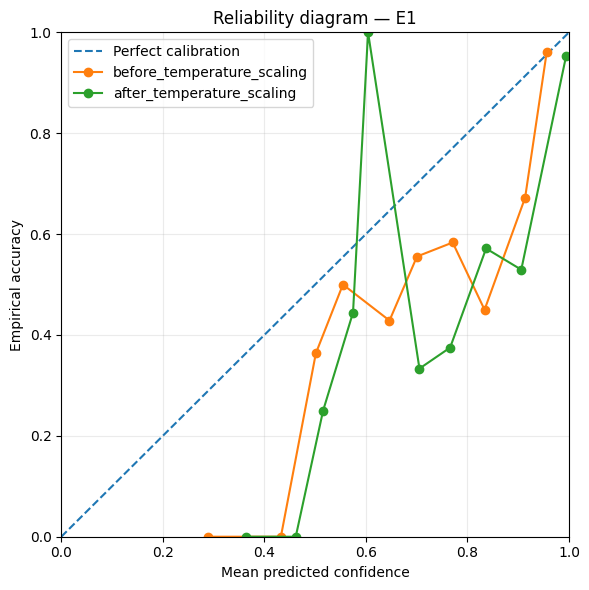

Normalized predictive entropy: mean= 0.0241 median= 0.0186


In [44]:

# cal_probs, raw_probs, conf, pred, accepted, and winner_test_labels were created above.
prob_eps = 1e-12
entropy_test = -(np.clip(cal_probs, prob_eps, 1.0) * np.log(np.clip(cal_probs, prob_eps, 1.0))).sum(axis=1)
normalized_entropy_test = entropy_test / np.log(9)
test_sample_ids = MANIFEST.loc[MANIFEST.official_split == "test", "sample_id"].astype(str).tolist()
assert len(test_sample_ids) == len(winner_test_labels)
winning_uncertainty_df = pd.DataFrame({
    "sample_id": test_sample_ids,
    "true_label": winner_test_labels.numpy().astype(int),
    "true_class": [CLASS_NAMES[int(x)] for x in winner_test_labels.numpy()],
    "predicted_label": pred.astype(int),
    "predicted_class": [CLASS_NAMES[int(x)] for x in pred],
    "correct": (pred == winner_test_labels.numpy()),
    "raw_max_probability": raw_probs.max(axis=1),
    "calibrated_max_probability": conf,
    "predictive_entropy": entropy_test,
    "normalized_entropy": normalized_entropy_test,
    "accepted_by_frozen_threshold": accepted,
    "temperature": TEMPERATURE,
    "acceptance_threshold": ACCEPTANCE_THRESHOLD,
})
atomic_csv_save(winning_uncertainty_df, DIRS["logs"] / "winning_model_test_uncertainty_predictions.csv")

# Reliability diagram: equal-width bins, matching the convention used by the ECE helper.
def reliability_points(y_true, probs, n_bins=15):
    y_true = np.asarray(y_true).astype(int)
    confs = np.asarray(probs).max(axis=1)
    preds = np.asarray(probs).argmax(axis=1)
    edges = np.linspace(0.0, 1.0, n_bins + 1)
    rows = []
    for b in range(n_bins):
        mask = (confs >= edges[b]) & ((confs <= edges[b+1]) if b == n_bins-1 else (confs < edges[b+1]))
        if mask.any():
            rows.append({"bin": b, "count": int(mask.sum()), "mean_confidence": float(confs[mask].mean()),
                         "empirical_accuracy": float((preds[mask] == y_true[mask]).mean())})
    return pd.DataFrame(rows)

rel_raw = reliability_points(winner_test_labels.numpy(), raw_probs)
rel_cal = reliability_points(winner_test_labels.numpy(), cal_probs)
rel_raw["stage"] = "before_temperature_scaling"
rel_cal["stage"] = "after_temperature_scaling"
reliability_df = pd.concat([rel_raw, rel_cal], ignore_index=True)
atomic_csv_save(reliability_df, DIRS["logs"] / "winning_model_reliability_bins.csv")
fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
for sub in [rel_raw, rel_cal]:
    ax.plot(sub.mean_confidence, sub.empirical_accuracy, marker="o", label=sub.stage.iloc[0])
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_xlabel("Mean predicted confidence"); ax.set_ylabel("Empirical accuracy")
ax.set_title(f"Reliability diagram — {WINNER_ID}"); ax.grid(alpha=.25); ax.legend(); plt.tight_layout()
fig.savefig(DIRS["figures"] / "winning_model_reliability_diagram.png", dpi=160); plt.show()
print("Normalized predictive entropy: mean=", round(float(normalized_entropy_test.mean()), 4),
      "median=", round(float(np.median(normalized_entropy_test)), 4))



## 36. Final test error analysis — descriptive only

The held-out test results are now used to describe model failures, not to change the winner or tune the method. This section exports all wrong predictions for the validation-selected model and the most frequent confusion pairs.


In [45]:

winner_test_rows = predictions_df[predictions_df.experiment_id == WINNER_ID].copy()
winner_test_rows["true_class"] = winner_test_rows.true_label.map(lambda x: CLASS_NAMES[int(x)])
winner_test_rows["predicted_class"] = winner_test_rows.predicted_label.map(lambda x: CLASS_NAMES[int(x)])
winner_test_rows["correct"] = winner_test_rows.true_label == winner_test_rows.predicted_label
wrong_test_df = winner_test_rows.loc[~winner_test_rows.correct].sort_values("max_probability", ascending=False)
atomic_csv_save(wrong_test_df, DIRS["logs"] / "winning_model_test_misclassifications.csv")
confusion_pairs = (wrong_test_df.groupby(["true_class", "predicted_class"], as_index=False)
                   .size().rename(columns={"size": "misclassification_count"})
                   .sort_values("misclassification_count", ascending=False))
atomic_csv_save(confusion_pairs, DIRS["logs"] / "winning_model_top_confusion_pairs.csv")
display(confusion_pairs.head(15))
print(f"Final test errors for {WINNER_ID}: {len(wrong_test_df)} / {len(winner_test_rows)}")


,true_class,predicted_class,misclassification_count
1,adipose,smooth muscle,33
6,cancer-associated stroma,smooth muscle,32
22,smooth muscle,cancer-associated stroma,32
9,colorectal adenocarcinoma epithelium,normal colon mucosa,12
16,mucus,normal colon mucosa,10
13,mucus,adipose,10
2,cancer-associated stroma,colorectal adenocarcinoma epithelium,8
8,colorectal adenocarcinoma epithelium,lymphocytes,8
7,colorectal adenocarcinoma epithelium,debris,8
18,normal colon mucosa,colorectal adenocarcinoma epithelium,7


Final test errors for E1: 192 / 3590



## 36A. Confusion matrices and per-class experiment comparison

Create one normalized/raw confusion-matrix figure for each experiment and a per-class Macro-F1 comparison across E1–E4. These plots help identify which tissue classes account for the aggregate differences. They describe the final test evaluation and must not be used to revise the selected model.


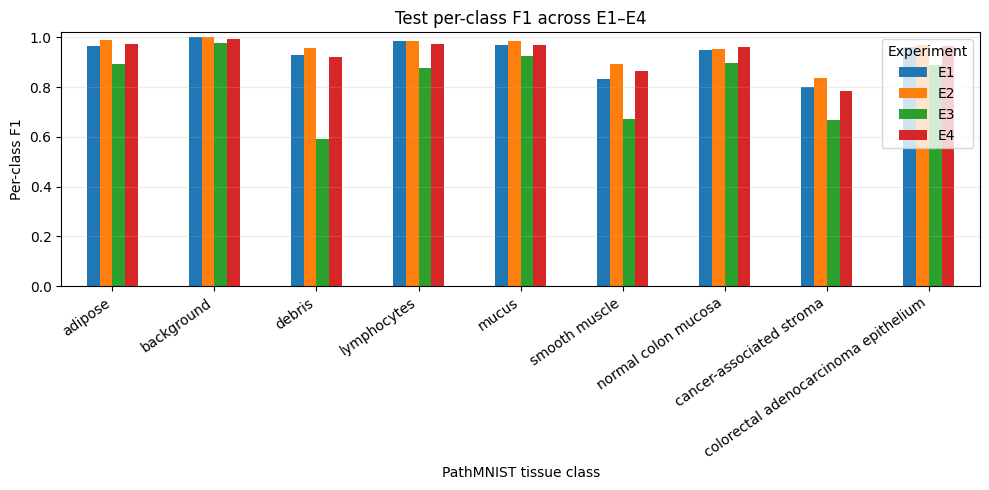

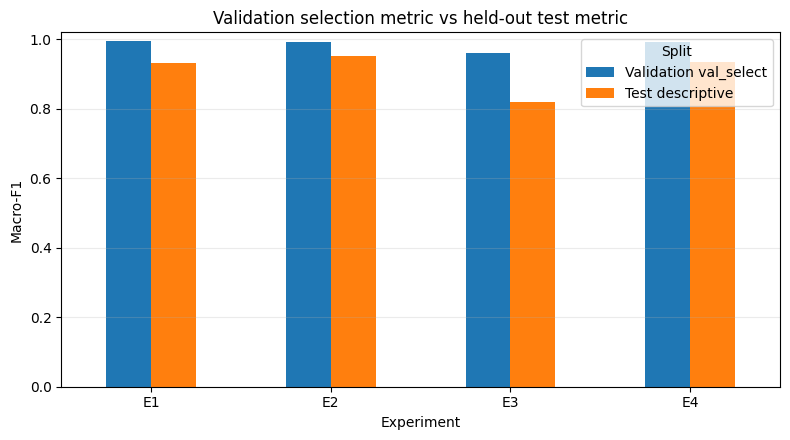

Confusion matrix figures: C:\Users\saibh\Videos\CV_MODEL\PathoLens_Workspace_50pct\figures\test_confusion_matrices
Per-class and split-comparison figures saved under: C:\Users\saibh\Videos\CV_MODEL\PathoLens_Workspace_50pct\figures


In [46]:

# Four confusion matrices, one per experiment.
cm_dir = DIRS["figures"] / "test_confusion_matrices"
cm_dir.mkdir(parents=True, exist_ok=True)
for exp_id in ["E1", "E2", "E3", "E4"]:
    sub = confusion_long_df[confusion_long_df.experiment_id == exp_id]
    cm = np.zeros((9, 9), dtype=int)
    for row in sub.itertuples(index=False):
        cm[int(row.true_class_id), int(row.pred_class_id)] = int(row.count)
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(9), CLASS_NAMES, rotation=45, ha="right")
    ax.set_yticks(range(9), CLASS_NAMES)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
    ax.set_title(f"{exp_id} — test confusion matrix (counts)")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    for r in range(9):
        for c in range(9):
            ax.text(c, r, str(cm[r, c]), ha="center", va="center", fontsize=7,
                    color="white" if cm[r, c] > cm.max() * 0.55 else "black")
    plt.tight_layout()
    fig.savefig(cm_dir / f"{exp_id}_test_confusion_matrix.png", dpi=160, bbox_inches="tight")
    plt.close(fig)

# Per-class F1 comparison across all four models.
f1_pivot = per_class_df.pivot(index="class_name", columns="experiment_id", values="f1").reindex(CLASS_NAMES)
fig, ax = plt.subplots(figsize=(10, 5))
f1_pivot.plot(kind="bar", ax=ax)
ax.set_ylabel("Per-class F1"); ax.set_xlabel("PathMNIST tissue class")
ax.set_title("Test per-class F1 across E1–E4")
ax.set_ylim(0, 1.02); ax.grid(axis="y", alpha=.25); ax.legend(title="Experiment")
plt.xticks(rotation=35, ha="right"); plt.tight_layout()
fig.savefig(DIRS["figures"] / "test_per_class_f1_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

# Validation-selected and test Macro-F1 are shown together, but only validation determines the winner.
plot_cmp = val_comparison[["experiment_id", "val_select_macro_f1"]].merge(
    test_summary_df[["experiment_id", "test_macro_f1"]], on="experiment_id", how="inner"
).set_index("experiment_id").reindex(["E1", "E2", "E3", "E4"])
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_cmp.plot(kind="bar", ax=ax)
ax.set_ylabel("Macro-F1"); ax.set_xlabel("Experiment")
ax.set_title("Validation selection metric vs held-out test metric")
ax.set_ylim(0, 1.02); ax.grid(axis="y", alpha=.25); ax.legend(["Validation val_select", "Test descriptive"], title="Split")
plt.xticks(rotation=0); plt.tight_layout()
fig.savefig(DIRS["figures"] / "validation_vs_test_macro_f1.png", dpi=160, bbox_inches="tight")
plt.show()
print("Confusion matrix figures:", cm_dir)
print("Per-class and split-comparison figures saved under:", DIRS["figures"])



## 37. Export the selected model and its frozen inference policy

The original four experiment checkpoints remain untouched. This export creates one additional bundle for the validation-selected model, including its state dictionary, architecture ID, preprocessing, class mapping, temperature, and abstention threshold. The bundle can be used by a later inference script or application.


In [47]:

selected_bundle_path = DIRS["exports"] / f"{WINNER_ID}_inference_bundle.pt"
selected_bundle = {
    "bundle_format_version": 1,
    "project_name": PROJECT_NAME,
    "experiment_id": WINNER_ID,
    "experiment_name": EXPERIMENTS[WINNER_ID]["name"],
    "model_id": EXPERIMENTS[WINNER_ID]["model_id"],
    "model_state_dict": {k: v.detach().cpu() for k, v in winner_model.state_dict().items()},
    "class_names": CLASS_NAMES,
    "class_to_id": CLASS_TO_ID,
    "input_size": IMAGE_SIZE,
    "normalization_mean": list(IMAGENET_MEAN),
    "normalization_std": list(IMAGENET_STD),
    "temperature": float(TEMPERATURE),
    "acceptance_threshold": float(ACCEPTANCE_THRESHOLD),
    "target_coverage_on_calibration": float(TARGET_COVERAGE),
    "selection_criterion": "highest val_select Macro-F1 across E1-E4",
    "best_epoch": int(winner_ckpt["best_epoch"]),
    "best_validation_macro_f1": float(winner_ckpt["best_val_macro_f1"]),
    "subset_sha256": SUBSET_SHA,
    "manifest_sha256": MANIFEST_SHA,
    "pretrained_sha256": PRETRAINED_SHA,
    "note": "Research prototype only; not clinically validated. Use identical preprocessing and model definition at inference.",
}
atomic_torch_save(selected_bundle, selected_bundle_path)
atomic_json_save({k: v for k, v in selected_bundle.items() if k != "model_state_dict"},
                 DIRS["exports"] / f"{WINNER_ID}_inference_config.json")
print("Inference bundle:", selected_bundle_path)
print("Bundle size (MB):", round(selected_bundle_path.stat().st_size / (1024**2), 3))


Inference bundle: C:\Users\saibh\Videos\CV_MODEL\PathoLens_Workspace_50pct\exports\E1_inference_bundle.pt
Bundle size (MB): 4.091



## 38. Final report and refreshed artifact inventory

The report below is generated from the current run's CSV outputs. It explicitly distinguishes validation-based checkpoint selection from descriptive test performance and records the pilot-subset and data-independence limitations.


In [48]:

# Refresh checkpoint audit and inventory after all analysis/export artifacts have been written.
val_winner_row = val_comparison.loc[val_comparison.experiment_id == WINNER_ID].iloc[0]
test_winner_row = test_summary_df.loc[test_summary_df.experiment_id == WINNER_ID].iloc[0]

report_lines = [
    "# PathoLens AI — Final Experiment Report",
    "",
    f"Generated (UTC): {datetime.now(timezone.utc).isoformat()}",
    "",
    "## Dataset and protocol",
    f"- Dataset: {DATASET_NAME}, size {DATA_SIZE}.",
    f"- Subset: {SUBSET_FRACTION:.0%} stratified sample from each official split; seed {SEED}.",
    f"- Samples: train={len(TRAIN_LABELS)}, validation={len(VAL_LABELS)}, test={len(TEST_LABELS)}.",
    f"- Validation roles: val_select={len(VAL_SELECT_LABELS)}, val_calib={len(VAL_CALIB_LABELS)}.",
    "- Test results are a pilot-subset evaluation, not full official-test performance.",
    "",
    "## Model selection",
    f"- Selected experiment: **{WINNER_ID} — {EXPERIMENTS[WINNER_ID]['name']}**.",
    f"- Selection criterion: highest val_select Macro-F1; best epoch={int(val_winner_row.best_epoch)}.",
    f"- Validation Macro-F1={float(val_winner_row.val_select_macro_f1):.6f}; validation accuracy={float(val_winner_row.val_select_accuracy):.6f}.",
    "- The test set was not used to select the checkpoint, temperature, or abstention threshold.",
    "",
    "## Test results (descriptive final evaluation)",
    f"- Test accuracy={float(test_winner_row.test_accuracy):.6f}.",
    f"- Test Macro-F1={float(test_winner_row.test_macro_f1):.6f}.",
    f"- Test balanced accuracy={float(test_winner_row.test_balanced_accuracy):.6f}.",
    f"- Test macro OVR AUC={float(test_winner_row.test_macro_ovr_auc):.6f}.",
    "",
    "## Calibration and selective prediction",
    f"- Temperature={float(TEMPERATURE):.6f}; fitted only on val_calib.",
    f"- Acceptance threshold={float(ACCEPTANCE_THRESHOLD):.6f}; selected on val_calib for target coverage {TARGET_COVERAGE:.0%}.",
    f"- Test coverage={float(coverage):.6f}; test selective accuracy={float(selective_accuracy):.6f}; test selective risk={float(selective_risk):.6f}.",
    f"- Test accepted={int(accepted.sum())}; abstained={int((~accepted).sum())}.",
    "",
    "## Experiment checkpoint comparison",
    "| ID | Experiment | Best epoch | Validation Macro-F1 | Test accuracy | Test Macro-F1 |",
    "|---|---|---:|---:|---:|---:|",
]
for _, row in val_comparison.sort_values("val_select_macro_f1", ascending=False).iterrows():
    test_row = test_summary_df.loc[test_summary_df.experiment_id == row.experiment_id].iloc[0]
    report_lines.append(
        f"| {row.experiment_id} | {row.experiment_name} | {int(row.best_epoch)} | {float(row.val_select_macro_f1):.6f} | {float(test_row.test_accuracy):.6f} | {float(test_row.test_macro_f1):.6f} |"
    )
report_lines += [
    "",
    "## Generated analysis artifacts",
    "- Training curves, class-distribution/EDA figures, confusion matrix data, per-class metrics, and per-image predictions.",
    "- Grad-CAM examples from validation data, detailed correct/error/uncertain examples, head-randomization sanity check, and rotation stability check.",
    "- Validation PCA embedding plot, calibration metrics, reliability diagram, predictive entropy, selective-prediction metrics, and risk–coverage curve.",
    "- Four-checkpoint audit and selected-model inference bundle.",
    "",
    "## Limitations and interpretation",
    "- This run uses a 50% PathMNIST-128 pilot subset. Do not describe these as full-dataset benchmark results.",
    "- The provided manifest and exact duplicate audit do not establish patient-level or slide-level independence.",
    "- Grad-CAM is a coarse class-score-associated heatmap, not pixel-level ground truth or proof of biological reasoning.",
    "- Calibration and selective prediction results are empirical on this subset and do not establish clinical safety.",
    "- PathoLens is a research prototype, not a clinically validated diagnostic system.",
]
report_path = DIRS["exports"] / "FINAL_EXPERIMENT_REPORT.md"
report_path.write_text("\n".join(report_lines), encoding="utf-8")

inventory_rows = []
for folder_name in ["shared_dataset", "pretrained", "derived_data", "experiments", "logs", "figures", "metadata", "exports"]:
    base_folder = WORKSPACE_ROOT / folder_name
    if base_folder.exists():
        for path in base_folder.rglob("*"):
            if path.is_file() and not path.name.endswith(".tmp"):
                inventory_rows.append({
                    "relative_path": str(path.relative_to(WORKSPACE_ROOT)),
                    "size_mb": round(path.stat().st_size / (1024**2), 4),
                    "sha256": sha256_file(path) if path.suffix in {".npz", ".pt", ".json", ".csv", ".md"} else "not_calculated",
                })
final_inventory_df = pd.DataFrame(inventory_rows).sort_values("relative_path")
atomic_csv_save(final_inventory_df, DIRS["metadata"] / "artifact_inventory_final.csv")
print("Final report:", report_path)
print("Final inventory:", DIRS["metadata"] / "artifact_inventory_final.csv")
display(final_inventory_df.head(30))


Final report: C:\Users\saibh\Videos\CV_MODEL\PathoLens_Workspace_50pct\exports\FINAL_EXPERIMENT_REPORT.md
Final inventory: C:\Users\saibh\Videos\CV_MODEL\PathoLens_Workspace_50pct\metadata\artifact_inventory_final.csv


,relative_path,size_mb,sha256
13,derived_data\macenko_reference.json,0.0007,dd63100f9681d36a994bfa99e97c50c6a498cfc5b8f475...
14,derived_data\macenko_test.npy,168.2814,not_calculated
15,derived_data\macenko_test_status.json,0.0002,e4bfe9740469b706e3e9e7803ce0e49a0acdd3881482c9...
16,derived_data\macenko_train.npy,2109.2814,not_calculated
17,derived_data\macenko_train_status.json,0.0002,a3af64ce32fb2a7cb685e434f14fbebbce06734f3cdaae...
18,derived_data\macenko_val.npy,234.4689,not_calculated
19,derived_data\macenko_val_status.json,0.0002,703cd471168b66df32ec10b33dbb97a8705d2f16bd21e8...
20,experiments\E1\best_model.pt,4.0879,3ca6a6417ab2bc085837cf1bcb0b41497bc89036e53f57...
21,experiments\E1\last_checkpoint.pt,12.1559,920d73277feabfa791454e4eb221bbe33cbb70f56a9091...
22,experiments\E2\best_model.pt,4.0879,018103b7dafa00508f95999f963fe23ccf11e5085a43c4...



## 39. Final completion gate

The project pipeline is complete only if all four verified best checkpoints exist, the validation comparison contains four experiments, and the final report and inference bundle were written. Review this table before treating the run as finished.


In [49]:

completion_checks = [
    ("four experiment checkpoints verified", len(checkpoint_audit_df) == 4 and checkpoint_audit_df.strict_state_dict_load.all()),
    ("validation comparison contains E1-E4", set(val_comparison.experiment_id) == {"E1", "E2", "E3", "E4"}),
    ("test comparison contains E1-E4", set(test_summary_df.experiment_id) == {"E1", "E2", "E3", "E4"}),
    ("Grad-CAM detailed manifest exists", (DIRS["logs"] / "gradcam_detailed_manifest.csv").exists()),
    ("Grad-CAM randomization check exists", (DIRS["logs"] / "gradcam_randomization_sanity.csv").exists()),
    ("Grad-CAM rotation stability exists", (DIRS["logs"] / "gradcam_rotation_stability.csv").exists()),
    ("calibration/reliability outputs exist", (DIRS["logs"] / "winning_model_reliability_bins.csv").exists()),
    ("final report exists", report_path.exists()),
    ("inference bundle exists", selected_bundle_path.exists()),
]
completion_df = pd.DataFrame(completion_checks, columns=["check", "passed"])
completion_df["status"] = np.where(completion_df.passed, "PASS", "FAIL")
display(completion_df)
if not completion_df.passed.all():
    raise RuntimeError("One or more completion checks failed. Read the failed check and its upstream cell output.")
print(f"PathoLens complete. Validation-selected model: {WINNER_ID} — {EXPERIMENTS[WINNER_ID]['name']}")


,check,passed,status
0,four experiment checkpoints verified,True,PASS
1,validation comparison contains E1-E4,True,PASS
2,test comparison contains E1-E4,True,PASS
3,Grad-CAM detailed manifest exists,True,PASS
4,Grad-CAM randomization check exists,True,PASS
5,Grad-CAM rotation stability exists,True,PASS
6,calibration/reliability outputs exist,True,PASS
7,final report exists,True,PASS
8,inference bundle exists,True,PASS


PathoLens complete. Validation-selected model: E1 — RGB baseline
